# SPRINT 1 — Comprensión del negocio y comprensión de datos
## HU01 — Definición del problema predictivo

**Proyecto de investigación:** *Modelo predictivo de horas de indisponibilidad operativa mediante Machine Learning considerando variables meteorológicas y oceanográficas en el Terminal Portuario ENGIE Perú, Ilo.*

**Marco metodológico:** CRISP-DM
**Sprint:** Sprint 1 — Semanas 1 y 2
**Épica:** Comprensión del Negocio
**Historia de usuario:** HU01 — Definición del problema predictivo
**Tareas cubiertas en este notebook:**
- **T01.** Identificación del problema de negocio del Terminal Portuario ENGIE-Ilo — **2 story points**.
- **T02.** Definición de las variables objetivo: inicio y duración de la indisponibilidad operativa dentro de un horizonte de 24 h — **3 story points**.

> **Alcance (T02):** el histórico disponible no solo registra el total de horas de indisponibilidad, sino que registra **fecha de inicio y fecha de fin de cada evento**. Esto permite que  en lugar de una única salida agregada, el modelo estimará **dos variables objetivo relacionadas con el próximo evento dentro del horizonte de 24 h**: (1) cuánto falta para que inicie y (2) cuánto durará. El fin del evento se deriva de ambas, no se modela directamente.


In [1]:
import pandas as pd
import numpy as np
from IPython.display import display, Markdown

pd.set_option('display.max_colwidth', 160)

proyecto = {
    'Organización / caso de estudio': 'Terminal Portuario ENGIE-Ilo',
    'Tipo de investigación': 'Aplicada - analítica predictiva',
    'Metodología de datos': 'CRISP-DM',
    'Marco de gestión': 'Scrum',
    'Sprint': 'Sprint 1 - Comprensión del negocio y comprensión de datos',
    'Historia de usuario': 'HU01 - Definición del problema predictivo',
    'Tarea 1': 'T01 - Identificación del problema de negocio',
    'Tarea 2': 'T02 - Definición de las variables objetivo (inicio y duración)',
    'Unidad temporal base': '1 hora',
    'Horizonte de predicción': '24 horas hacia adelante (t, t+24h] — el evento ocurre DENTRO de esta ventana',
    'Tipo de problema ML': 'Regresión supervisada (doble salida) + clasificación auxiliar de ocurrencia(https://prnt.sc/R94ZM2Ft8oRR)',
    'Variable objetivo 1': 'Horas desde t hasta el inicio del próximo evento de indisponibilidad (horas_hasta_inicio_24h)',
    'Variable objetivo 2': 'Duración del evento de indisponibilidad en horas (duracion_indisponibilidad_h)',
    'Variable derivada (no modelada)': 'Hora de fin del evento = t + horas_hasta_inicio_24h + duracion_indisponibilidad_h',
    'Familia de algoritmos planificada': 'GBM — Gradient Boosting (XGBoost, LightGBM) y variantes (Random Forest como referencia)'
}

display(pd.DataFrame(proyecto.items(), columns=['Elemento', 'Definición']))


,Elemento,Definición
0,Organización / caso de estudio,Terminal Portuario ENGIE-Ilo
1,Tipo de investigación,Aplicada - analítica predictiva
2,Metodología de datos,CRISP-DM
3,Marco de gestión,Scrum
4,Sprint,Sprint 1 - Comprensión del negocio y comprensión de datos
5,Historia de usuario,HU01 - Definición del problema predictivo
6,Tarea 1,T01 - Identificación del problema de negocio
7,Tarea 2,T02 - Definición de las variables objetivo (inicio y duración)
8,Unidad temporal base,1 hora
9,Horizonte de predicción,"24 horas hacia adelante (t, t+24h] — el evento ocurre DENTRO de esta ventana"


In [2]:
# ==== Configuración visual compartida por los diagramas de este notebook ====
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Rectangle

COLOR_NAVY    = '#1B3A5C'   # estructura / texto principal
COLOR_TEAL    = '#2A9D8F'   # disponible / cumplido / predictor
COLOR_TEAL_LT = '#D6EFEC'
COLOR_ORANGE  = '#E9762B'   # pendiente / validar con negocio
COLOR_RED     = '#C43D3D'   # riesgo / prohibido (data leakage)
COLOR_GRAY    = '#9AA5B1'   # fuera de alcance / derivado
COLOR_GRAY_LT = '#EEF1F4'
COLOR_GOLD    = '#E3A857'   # evento / indisponibilidad

plt.rcParams['font.family'] = 'DejaVu Sans'

def caja(ax, x, y, w, h, texto, color=COLOR_NAVY, texto_color='white',
         fontsize=10.5, fontweight='bold'):
    """Dibuja un recuadro redondeado con texto centrado."""
    box = FancyBboxPatch((x, y), w, h,
                          boxstyle='round,pad=0.02,rounding_size=0.05',
                          linewidth=1.5, edgecolor=color, facecolor=color, zorder=2)
    ax.add_patch(box)
    ax.text(x + w/2, y + h/2, texto, ha='center', va='center',
            fontsize=fontsize, color=texto_color, fontweight=fontweight,
            zorder=3, linespacing=1.35)
    return box

def flecha(ax, p1, p2, color=COLOR_NAVY, lw=1.8, style='-|>', rad=0.0):
    """Dibuja una flecha curva/recta entre dos puntos."""
    arr = FancyArrowPatch(p1, p2, arrowstyle=style, mutation_scale=15,
                           color=color, lw=lw,
                           connectionstyle=f'arc3,rad={rad}', zorder=1)
    ax.add_patch(arr)

def lienzo(w=11, h=5, xlim=(0, 11), ylim=(0, 5)):
    """Crea una figura/ejes en blanco (sin bordes) del tamaño indicado."""
    fig, ax = plt.subplots(figsize=(w, h))
    ax.set_xlim(*xlim); ax.set_ylim(*ylim)
    ax.axis('off')
    return fig, ax


### Vista rápida: la idea completa en un solo gráfico

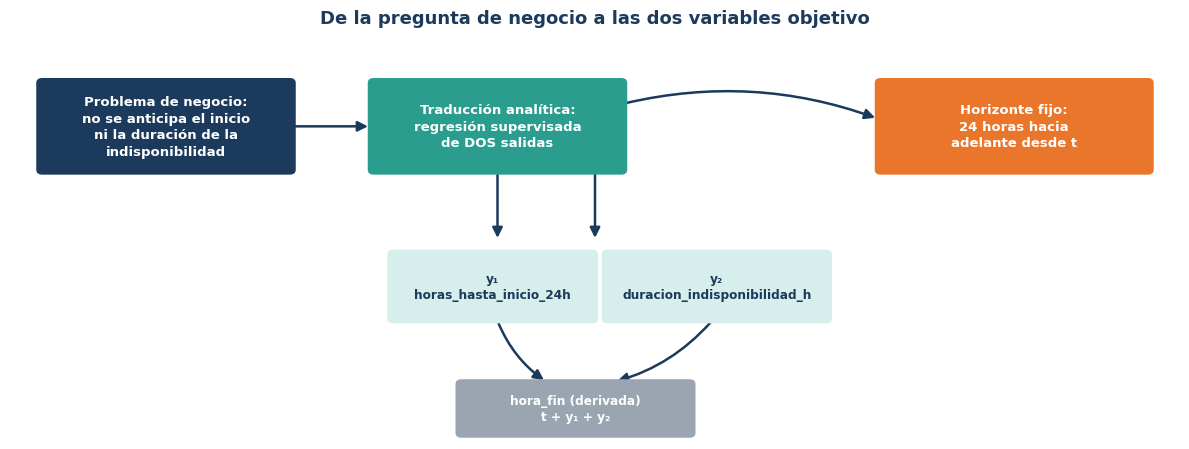

In [3]:
fig, ax = lienzo(12, 4.6, xlim=(0, 12), ylim=(0, 5.2))
ax.set_title('De la pregunta de negocio a las dos variables objetivo', fontsize=13,
             color=COLOR_NAVY, fontweight='bold', pad=14)

caja(ax, 0.3, 3.5, 2.6, 1.2, 'Problema de negocio:\nno se anticipa el inicio\nni la duración de la\nindisponibilidad', color=COLOR_NAVY, fontsize=9.5)
flecha(ax, (2.9, 4.1), (3.7, 4.1))
caja(ax, 3.7, 3.5, 2.6, 1.2, 'Traducción analítica:\nregresión supervisada\nde DOS salidas', color=COLOR_TEAL, fontsize=9.5)
flecha(ax, (5.0, 3.5), (5.0, 2.6))
flecha(ax, (6.0, 3.5), (6.0, 2.6))

caja(ax, 3.9, 1.55, 2.1, 0.9, 'y\u2081\nhoras_hasta_inicio_24h', color=COLOR_TEAL_LT, texto_color=COLOR_NAVY, fontsize=8.7)
caja(ax, 6.1, 1.55, 2.3, 0.9, 'y\u2082\nduracion_indisponibilidad_h', color=COLOR_TEAL_LT, texto_color=COLOR_NAVY, fontsize=8.7)

flecha(ax, (5.0, 1.55), (5.5, 0.75), rad=0.15)
flecha(ax, (7.2, 1.55), (6.2, 0.75), rad=-0.15)
caja(ax, 4.6, 0.05, 2.4, 0.7, 'hora_fin (derivada)\nt + y\u2081 + y\u2082', color=COLOR_GRAY, fontsize=8.7)

caja(ax, 8.9, 3.5, 2.8, 1.2, 'Horizonte fijo:\n24 horas hacia\nadelante desde t', color=COLOR_ORANGE, fontsize=9.5)
flecha(ax, (6.3, 4.4), (8.9, 4.2), rad=-0.15)

plt.tight_layout()
plt.show()


## 1. Ubicación de HU01 dentro de CRISP-DM

CRISP-DM organiza el trabajo analítico en fases iterativas. En nuestro proyecto, HU01 pertenece principalmente a **Comprensión del Negocio**, porque antes de manipular datos o entrenar modelos es necesario establecer **qué decisión empresarial se desea mejorar**, **qué fenómeno será predicho** y **cómo se expresará cuantitativamente el resultado esperado**.

La relación con **Comprensión de los Datos** en este punto es deliberadamente limitada: solo se registra qué fuentes deben existir para hacer viable la predicción y qué restricciones temporales presentan. La importación, integración y exploración detallada corresponden a HU03 y HU04. Sin embargo, en esta versión de HU01 que presentamos,sí se deja establecida la **estructura de las fuentes** (variables meteo-oceanográficas por archivo y registro histórico de eventos con inicio/fin), porque de ella depende directamente cómo se construyen las dos variables objetivo.


In [4]:
crisp_dm_hu01 = pd.DataFrame([
    ['Comprensión del negocio', 'Objetivos del negocio', 'Determinar qué problema operativo necesita anticipación', 'T01'],
    ['Comprensión del negocio', 'Objetivo de minería de datos', 'Traducir la necesidad operativa a un problema de regresión de doble salida (inicio y duración)', 'T01'],
    ['Comprensión del negocio', 'Criterio analítico', 'Definir qué dos resultados numéricos se desea estimar y cómo se deriva el fin del evento', 'T02'],
    ['Comprensión del negocio', 'Restricciones', 'Fijar unidad temporal, horizonte (evento dentro de 24h) y reglas de las dos etiquetas', 'T02'],
    ['Comprensión de los datos', 'Inventario inicial', 'Identificar archivos Excel de variables meteo-oceanográficas y el histórico de eventos con inicio/fin', 'Puente hacia HU03'],
])
crisp_dm_hu01.columns = ['Fase CRISP-DM', 'Componente', 'Aplicación al proyecto', 'Trazabilidad']
display(crisp_dm_hu01)


,Fase CRISP-DM,Componente,Aplicación al proyecto,Trazabilidad
0,Comprensión del negocio,Objetivos del negocio,Determinar qué problema operativo necesita anticipación,T01
1,Comprensión del negocio,Objetivo de minería de datos,Traducir la necesidad operativa a un problema de regresión de doble salida (inicio y duración),T01
2,Comprensión del negocio,Criterio analítico,Definir qué dos resultados numéricos se desea estimar y cómo se deriva el fin del evento,T02
3,Comprensión del negocio,Restricciones,"Fijar unidad temporal, horizonte (evento dentro de 24h) y reglas de las dos etiquetas",T02
4,Comprensión de los datos,Inventario inicial,Identificar archivos Excel de variables meteo-oceanográficas y el histórico de eventos con inicio/fin,Puente hacia HU03


**Vista visual**

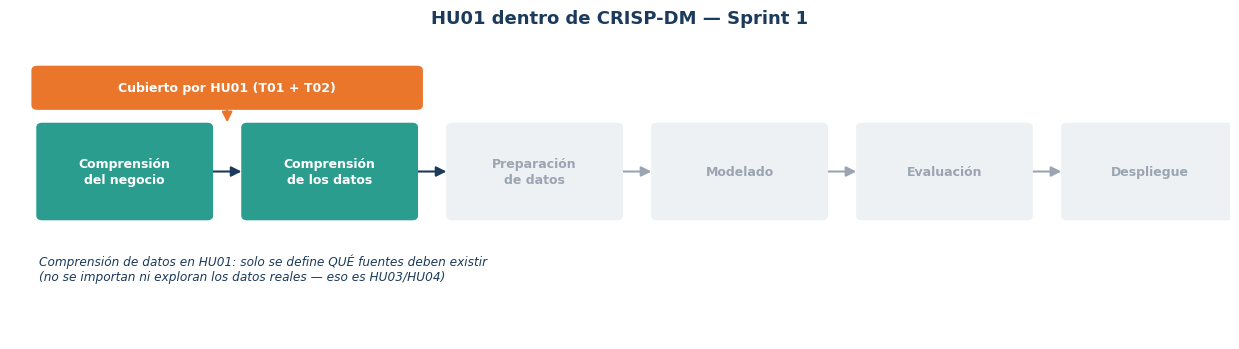

In [5]:
fases = ['Comprensión\ndel negocio', 'Comprensión\nde los datos', 'Preparación\nde datos', 'Modelado', 'Evaluación', 'Despliegue']
activo = [True, True, False, False, False, False]

fig, ax = lienzo(12.5, 3.6, xlim=(0, 12.5), ylim=(0, 4.2))
ax.set_title('HU01 dentro de CRISP-DM — Sprint 1', fontsize=13, color=COLOR_NAVY, fontweight='bold', pad=12)

n = len(fases)
w, gap = 1.75, 0.35
x0 = 0.3
for i, (f, a) in enumerate(zip(fases, activo)):
    x = x0 + i * (w + gap)
    color = COLOR_TEAL if a else COLOR_GRAY_LT
    tcolor = 'white' if a else COLOR_GRAY
    caja(ax, x, 1.7, w, 1.3, f, color=color, texto_color=tcolor, fontsize=9)
    if i < n - 1:
        flecha(ax, (x + w, 2.35), (x + w + gap, 2.35), color=COLOR_NAVY if a else COLOR_GRAY, lw=1.5)

caja(ax, x0 - 0.05, 3.25, 2*w + gap + 0.1, 0.55, 'Cubierto por HU01 (T01 + T02)', color=COLOR_ORANGE, fontsize=9)
flecha(ax, (x0 + (2*w + gap)/2, 3.25), (x0 + (2*w + gap)/2, 3.0), color=COLOR_ORANGE, lw=1.6)

ax.text(x0, 1.2, 'Comprensión de datos en HU01: solo se define QUÉ fuentes deben existir\n(no se importan ni exploran los datos reales — eso es HU03/HU04)',
        fontsize=8.7, color=COLOR_NAVY, ha='left', va='top', style='italic')

plt.tight_layout()
plt.show()


## 2. HU01 — Definición del problema predictivo

**Historia de usuario formalizada:**
*Como investigador, quiero definir el problema de predicción del inicio y la duración de la indisponibilidad operativa del Terminal Portuario ENGIE-Ilo, para establecer claramente el objetivo del modelo de Machine Learning.*

### Criterios de aceptación propuestos para HU01

1. El problema de negocio debe estar descrito sin confundirlo con la solución tecnológica.
2. Debe documentarse el proceso actual (*As-Is*) que evidencia la necesidad de anticipación.
3. La necesidad empresarial debe traducirse a un problema analítico explícito.
4. **Las dos variables objetivo** (inicio y duración) deben tener definición semántica, unidad, tipo estadístico, temporalidad y fuente.
5. Deben quedar identificadas las decisiones abiertas que requieren validación de un experto de Operaciones, incluyendo el manejo de horizontes sin evento y de eventos múltiples.
6. La definición debe ser compatible con la secuencia temporal del proyecto y evitar el uso de información futura como predictor (*data leakage*).


# T01 — Identificar el problema de negocio del Terminal Portuario ENGIE-Ilo

## 2.1 Contexto operativo relevante

El Terminal Portuario ENGIE-Ilo opera en un entorno costero expuesto a variaciones **meteorológicas y oceanográficas**. Contamos con variables relevantes: la velocidad y dirección del viento, temperatura, humedad, presión atmosférica y oleaje. Estas condiciones pueden restringir temporalmente maniobras, suspender operaciones y generar períodos de indisponibilidad.

La necesidad no surge porque el terminal carezca de observación del entorno. El problema central es que el proceso actual es predominantemente **reactivo**: el personal observa las condiciones, comunica una alerta, se decide la suspensión cuando la afectación ya se manifiesta y luego se espera hasta que las condiciones mejoren. **El inicio y la duración de la indisponibilidad se conocen recién después del evento**, cuando se registran manualmente.

### Proceso actual (*As-Is*) resumido

1. Observación empírica de oleaje y viento por personal de campo.
2. Comunicación de la condición al supervisor o jefe de Operaciones.
3. Decisión reactiva de suspensión de la maniobra.
4. Espera y seguimiento hasta la mejora de las condiciones.
5. Reanudación de la maniobra.
6. Registro manual del **inicio, fin y duración** de la indisponibilidad.

El punto crítico para esta investigación se ubica entre los pasos 2 y 4: **no existe una estimación anticipada de cuándo empezará la indisponibilidad ni de cuánto podría durar**.


**Vista visual — el proceso reactivo actual:**

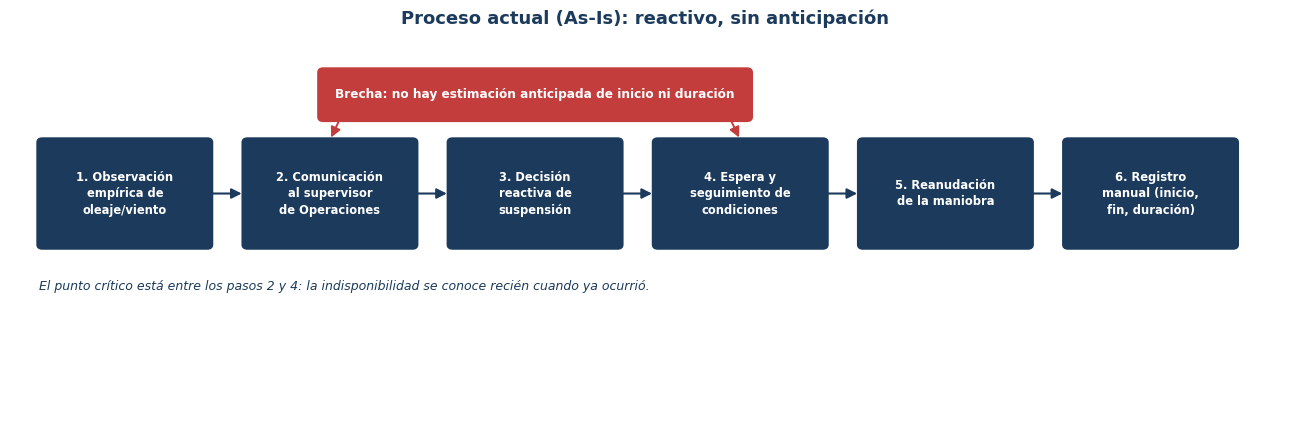

In [6]:
pasos = ['1. Observación\nempírica de\noleaje/viento', '2. Comunicación\nal supervisor\nde Operaciones',
         '3. Decisión\nreactiva de\nsuspensión', '4. Espera y\nseguimiento de\ncondiciones',
         '5. Reanudación\nde la maniobra', '6. Registro\nmanual (inicio,\nfin, duración)']

fig, ax = lienzo(13, 4.4, xlim=(0, 13), ylim=(0, 4.6))
ax.set_title('Proceso actual (As-Is): reactivo, sin anticipación', fontsize=13, color=COLOR_NAVY, fontweight='bold', pad=12)

n = len(pasos)
w, gap = 1.75, 0.35
x0 = 0.3
for i, p in enumerate(pasos):
    x = x0 + i * (w + gap)
    caja(ax, x, 2.1, w, 1.3, p, color=COLOR_NAVY, fontsize=8.3)
    if i < n - 1:
        flecha(ax, (x + w, 2.75), (x + w + gap, 2.75), color=COLOR_NAVY, lw=1.5)

x_ini = x0 + 1*(w + gap) + w*0.5
x_fin = x0 + 3*(w + gap) + w*0.5
caja(ax, x_ini - 0.1, 3.65, (x_fin - x_ini) + 0.2, 0.6, 'Brecha: no hay estimación anticipada de inicio ni duración', color=COLOR_RED, fontsize=8.7)
flecha(ax, (x_ini + 0.1, 3.65), (x0 + 1*(w + gap) + w/2, 3.4), color=COLOR_RED, lw=1.4)
flecha(ax, (x_fin - 0.1, 3.65), (x0 + 3*(w + gap) + w/2, 3.4), color=COLOR_RED, lw=1.4)

ax.text(x0, 1.7, 'El punto crítico está entre los pasos 2 y 4: la indisponibilidad se conoce recién cuando ya ocurrió.',
        fontsize=9, color=COLOR_NAVY, ha='left', va='top', style='italic')

plt.tight_layout()
plt.show()


## 2.2 Formulación del problema de negocio

> **Problema de negocio:** El Terminal Portuario ENGIE-Ilo presenta una capacidad limitada para anticipar **el momento de inicio y la duración** de los períodos de indisponibilidad operativa asociados a condiciones meteorológicas y oceanográficas adversas. Como consecuencia, la planificación de maniobras, la asignación de recursos y la continuidad de las operaciones se gestionan con menor anticipación de la deseable y bajo un esquema principalmente reactivo.

Esta formulación evita definir prematuramente un algoritmo. El problema empresarial es **la falta de anticipación útil para planificar** (cuándo y por cuánto tiempo); Machine Learning es la alternativa tecnológica que la investigación evaluará posteriormente.

### Impacto operativo esperado del problema

- Incertidumbre para programar actividades y ventanas operativas.
- Dificultad para asignar recursos con anticipación.
- Riesgo de tiempos improductivos durante suspensiones.
- Menor capacidad para coordinar decisiones preventivas frente a condiciones adversas.
- Dependencia elevada de observación y experiencia inmediata del personal.


In [ ]:
matriz_problema = pd.DataFrame([
    ['Condiciones ambientales', 'Variaciones de viento, oleaje y variables atmosféricas', 'Pueden restringir o suspender maniobras'],
    ['Proceso actual', 'Observación y decisión predominantemente reactiva', 'La respuesta se activa cuando la condición ya afecta la operación'],
    ['Brecha de información', 'No se dispone de una estimación previa de inicio ni de duración', 'La planificación futura queda limitada en dos dimensiones: cuándo y por cuánto tiempo'],
    ['Dato histórico', 'Se registran fecha de inicio y fecha de fin de cada evento (la duración se deriva de ambas)', 'Existe base suficiente para construir DOS etiquetas predictivas, no solo una agregada'],
    ['Necesidad de negocio', 'Anticipar cuándo iniciará y cuánto durará la indisponibilidad', 'Apoyar programación, asignación de recursos y toma de decisiones']
], columns=['Dimensión', 'Situación identificada', 'Implicancia'])

display(matriz_problema)


,Dimensión,Situación identificada,Implicancia
0,Condiciones ambientales,"Variaciones de viento, oleaje y variables atmosféricas",Pueden restringir o suspender maniobras
1,Proceso actual,Observación y decisión predominantemente reactiva,La respuesta se activa cuando la condición ya afecta la operación
2,Brecha de información,No se dispone de una estimación previa de inicio ni de duración,La planificación futura queda limitada en dos dimensiones: cuándo y por cuánto tiempo
3,Dato histórico,Se registran fecha de inicio y fecha de fin de cada evento (la duración se deriva de ambas),"Existe base suficiente para construir DOS etiquetas predictivas, no solo una agregada"
4,Necesidad de negocio,Anticipar cuándo iniciará y cuánto durará la indisponibilidad,"Apoyar programación, asignación de recursos y toma de decisiones"


## 2.3 Pregunta de investigación y traducción al problema analítico

La formulación de investigación del documento base es:

> **¿De qué manera un modelo basado en Machine Learning, considerando variables meteorológicas, podría predecir las horas de indisponibilidad operativa en el Terminal Portuario ENGIE Perú, Ilo?**

Dado que el histórico permite conocer inicio y fin de cada evento (no solo el total de horas), esta pregunta se traduce en dos preguntas analíticas complementarias, ambas resueltas a partir de la misma ventana de predictores $X_{\le t}$:

1. **¿Cuánto tiempo falta, desde $t$, para que inicie el próximo evento de indisponibilidad, dado que ese inicio ocurre dentro de las siguientes 24 horas?**
2. **¿Cuánto durará ese evento una vez que inicie?**

## 2.4 Reformulación del problema a partir de la disponibilidad de inicio y fin en el histórico

Para el T02 se presenta que el modelo debe entregar **dos salidas relacionadas con el evento más próximo dentro del horizonte**, de forma que el inicio y el fin puedan reconstruirse explícitamente. Esta reformulación no cambia el horizonte de 24 horas ni la familia de algoritmos planificada (GBM); cambia **qué variable(s) se le pide aprender al modelo**.


# T02 — Definir las variables objetivo: inicio y duración de la indisponibilidad operativa

## 3.1 Fuentes de datos disponibles

Antes de definir las variables objetivo, se deja establecida la estructura de las fuentes que las hacen posibles, ya que ambas provienen de tablas distintas que deben integrarse por fecha-hora:


In [ ]:
fuentes_datos = pd.DataFrame([
    ['Velocidad del viento', 'Archivo Excel independiente', 'fecha_hora, velocidad_viento_mph', 'Casi-continua (segundos/minutos)', 'Predictor (X)'],
    ['Dirección del viento', 'Archivo Excel independiente', 'fecha_hora, direccion_viento_deg', 'Casi-continua (segundos/minutos)', 'Predictor (X)'],
    ['Temperatura ambiental', 'Archivo Excel independiente', 'fecha_hora, temperatura_c', 'Casi-continua (segundos/minutos)', 'Predictor (X)'],
    ['Humedad relativa', 'Archivo Excel independiente', 'fecha_hora, humedad_relativa_pct', 'Casi-continua (segundos/minutos)', 'Predictor (X)'],
    ['Presión atmosférica', 'Archivo Excel independiente', 'fecha_hora, presion_atmosferica_hpa', 'Casi-continua (segundos/minutos)', 'Predictor (X)'],
    ['Altura de olas', 'Archivo Excel independiente', 'fecha_hora, altura_olas_m', 'Casi-continua (segundos/minutos)', 'Predictor (X)'],
    ['Histórico de indisponibilidad', 'Archivo Excel de eventos', 'fecha_inicio, fecha_fin (duración = fecha_fin - fecha_inicio)', 'Un registro por evento', 'Fuente de las DOS variables objetivo (y)'],
], columns=['Variable / Registro', 'Formato de origen', 'Columnas clave', 'Granularidad', 'Rol en el modelo'])

display(fuentes_datos)


,Variable / Registro,Formato de origen,Columnas clave,Granularidad,Rol en el modelo
0,Velocidad del viento,Archivo Excel independiente,"fecha_hora, velocidad_viento_mph",Casi-continua (segundos/minutos),Predictor (X)
1,Dirección del viento,Archivo Excel independiente,"fecha_hora, direccion_viento_deg",Casi-continua (segundos/minutos),Predictor (X)
2,Temperatura ambiental,Archivo Excel independiente,"fecha_hora, temperatura_c",Casi-continua (segundos/minutos),Predictor (X)
3,Humedad relativa,Archivo Excel independiente,"fecha_hora, humedad_relativa_pct",Casi-continua (segundos/minutos),Predictor (X)
4,Presión atmosférica,Archivo Excel independiente,"fecha_hora, presion_atmosferica_hpa",Casi-continua (segundos/minutos),Predictor (X)
5,Altura de olas,Archivo Excel independiente,"fecha_hora, altura_olas_m",Casi-continua (segundos/minutos),Predictor (X)
6,Histórico de indisponibilidad,Archivo Excel de eventos,"fecha_inicio, fecha_fin (duración = fecha_fin - fecha_inicio)",Un registro por evento,Fuente de las DOS variables objetivo (y)


**Vista visual — de las fuentes al conjunto de predictores y targets:**

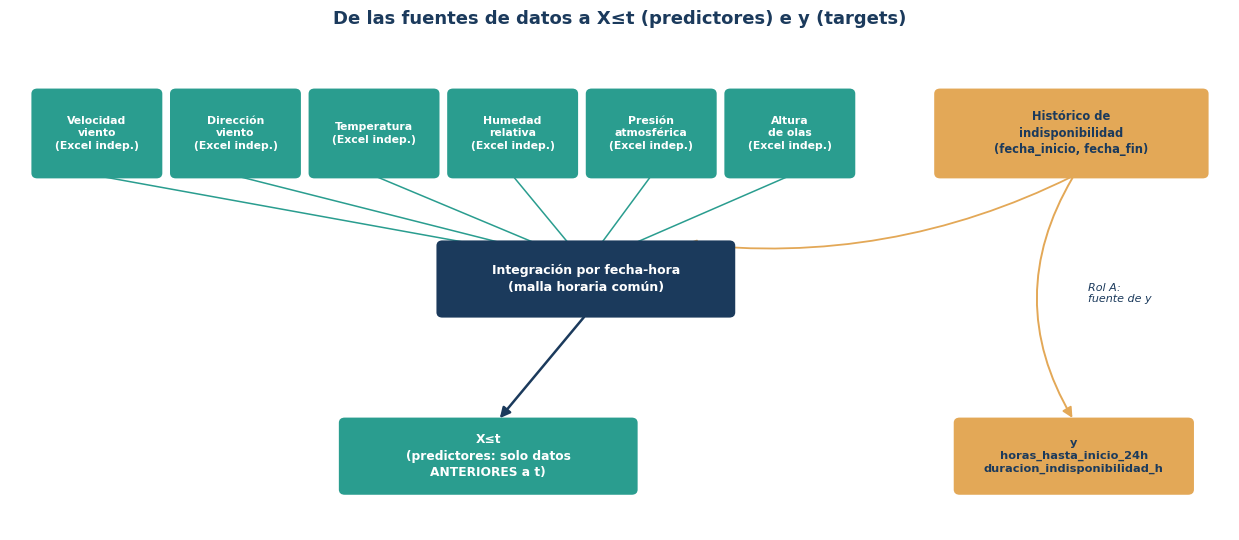

In [7]:
variables = ['Velocidad\nviento', 'Dirección\nviento', 'Temperatura', 'Humedad\nrelativa', 'Presión\natmosférica', 'Altura\nde olas']

fig, ax = lienzo(12.5, 5.5, xlim=(0, 12.5), ylim=(0, 5.8))
ax.set_title('De las fuentes de datos a X\u2264t (predictores) e y (targets)', fontsize=13, color=COLOR_NAVY, fontweight='bold', pad=12)

x0 = 0.25
w, gap = 1.28, 0.14
for i, v in enumerate(variables):
    x = x0 + i * (w + gap)
    caja(ax, x, 4.2, w, 1.0, v + '\n(Excel indep.)', color=COLOR_TEAL, fontsize=7.8)
    flecha(ax, (x + w/2, 4.2), (5.9, 3.15), color=COLOR_TEAL, lw=1.1)

caja(ax, 9.5, 4.2, 2.75, 1.0, 'Histórico de\nindisponibilidad\n(fecha_inicio, fecha_fin)', color=COLOR_GOLD, texto_color=COLOR_NAVY, fontsize=8.3)

caja(ax, 4.4, 2.55, 3.0, 0.85, 'Integración por fecha-hora\n(malla horaria común)', color=COLOR_NAVY, fontsize=9)
flecha(ax, (10.9, 4.2), (6.9, 3.4), color=COLOR_GOLD, lw=1.3, rad=-0.15)
flecha(ax, (10.9, 4.2), (10.9, 1.3), color=COLOR_GOLD, lw=1.4, rad=0.3)
ax.text(11.05, 2.7, 'Rol A:\nfuente de y', fontsize=8, color=COLOR_NAVY, style='italic')

flecha(ax, (5.9, 2.55), (5.0, 1.3))
caja(ax, 3.4, 0.45, 3.0, 0.85, 'X\u2264t\n(predictores: solo datos\nANTERIORES a t)', color=COLOR_TEAL, fontsize=8.8)

caja(ax, 9.7, 0.45, 2.4, 0.85, 'y\nhoras_hasta_inicio_24h\nduracion_indisponibilidad_h', color=COLOR_GOLD, texto_color=COLOR_NAVY, fontsize=8.2)

plt.tight_layout()
plt.show()


## 3.1.1 Dos roles distintos del histórico de indisponibilidad

Es importante distinguir, desde ya, **dos usos del mismo histórico de eventos**, porque ambos alimentan al Machine Learning pero de forma distinta:

**Rol A — Fuente de las etiquetas `y`.** `fecha_inicio` y `fecha_fin` de cada evento generan `horas_hasta_inicio_24h` y `duracion_indisponibilidad_h` (sección 3.3). Esto es lo que el modelo aprende a predecir.

**Rol B — Caracterización del evento (evidencia causal, no predictor).** Mientras el terminal está indisponible (por ejemplo, del 17/09/2026 20:25 al 17/09/2026 21:25), el sensor meteo-oceanográficos **siguen registrando en simultáneo**. Esas lecturas dicen qué condiciones acompañaron o causaron esa indisponibilidad específica, y sirven para: (i) confirmar que el evento tiene causa meteo-oceanográfica y no otra (control **Q04**, decisión **D02**); (ii) el análisis exploratorio que justifica qué variable(s) y qué umbrales típicamente preceden un evento.

> **Regla que no debe romperse (Q07 — anti data-leakage):** las lecturas registradas *durante* el evento (20:25–21:25 en el ejemplo) **entrenan indirectamente** al modelo — porque ayudan a etiquetar y entender el fenómeno — pero **nunca entran como columnas de `X_≤t`** para predecir ese mismo evento. El modelo, en producción, se ejecuta en un instante `t` anterior al inicio (ej. a las 19:00) y en ese momento las lecturas de las 20:25–21:25 todavía no existen. `X_≤t` se construye exclusivamente con la ventana de lookback **anterior** a `fecha_inicio`, nunca con la ventana interior al evento.


**Vista visual — qué puede y qué no puede usarse como predictor (Q07):**

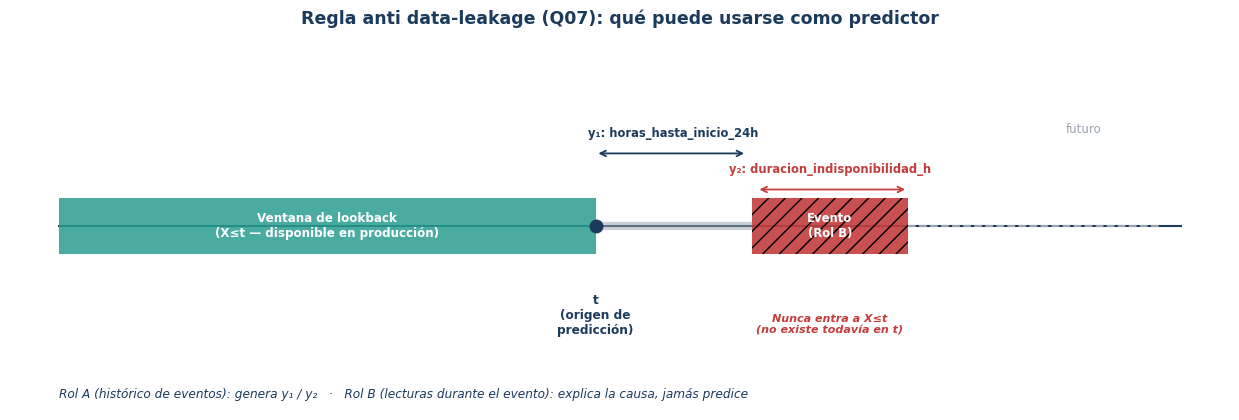

In [8]:
fig, ax = lienzo(12.5, 4.3, xlim=(0, 12.5), ylim=(0, 4.6))
ax.set_title('Regla anti data-leakage (Q07): qué puede usarse como predictor', fontsize=12.5, color=COLOR_NAVY, fontweight='bold', pad=12)

y_line = 2.3
ax.plot([0.5, 12.0], [y_line, y_line], color=COLOR_NAVY, lw=1.5, zorder=1)

rect1 = Rectangle((0.5, y_line - 0.35), 5.5, 0.7, facecolor=COLOR_TEAL, alpha=0.85, zorder=2)
ax.add_patch(rect1)
ax.text(3.25, y_line, 'Ventana de lookback\n(X\u2264t — disponible en producción)', ha='center', va='center', fontsize=8.6, color='white', fontweight='bold')

ax.plot([6.0], [y_line], marker='o', color=COLOR_NAVY, markersize=9, zorder=3)
ax.text(6.0, y_line - 1.35, 't\n(origen de\npredicción)', ha='center', fontsize=8.7, color=COLOR_NAVY, fontweight='bold')

ax.plot([6.0, 7.6], [y_line, y_line], color=COLOR_GRAY, lw=6, alpha=0.5, zorder=1, solid_capstyle='butt')

rect2 = Rectangle((7.6, y_line - 0.35), 1.6, 0.7, facecolor=COLOR_RED, alpha=0.9, hatch='//', zorder=2)
ax.add_patch(rect2)
ax.text(8.4, y_line, 'Evento\n(Rol B)', ha='center', va='center', fontsize=8.4, color='white', fontweight='bold')
ax.text(8.4, y_line - 1.35, 'Nunca entra a X\u2264t\n(no existe todavía en t)', ha='center', fontsize=8, color=COLOR_RED, style='italic', fontweight='bold')

ax.plot([9.2, 11.8], [y_line, y_line], color=COLOR_GRAY, lw=1.5, ls='--', zorder=1)
ax.text(11.0, y_line + 1.15, 'futuro', ha='center', fontsize=8.5, color=COLOR_GRAY)

ax.annotate('', xy=(7.55, y_line + 0.9), xytext=(6.0, y_line + 0.9),
            arrowprops=dict(arrowstyle='<->', color=COLOR_NAVY, lw=1.3))
ax.text(6.8, y_line + 1.1, 'y\u2081: horas_hasta_inicio_24h', ha='center', fontsize=8.3, color=COLOR_NAVY, fontweight='bold')

ax.annotate('', xy=(9.2, y_line + 0.45), xytext=(7.65, y_line + 0.45),
            arrowprops=dict(arrowstyle='<->', color=COLOR_RED, lw=1.3))
ax.text(8.4, y_line + 0.65, 'y\u2082: duracion_indisponibilidad_h', ha='center', fontsize=8.3, color=COLOR_RED, fontweight='bold')

ax.text(0.5, 0.15, 'Rol A (histórico de eventos): genera y\u2081 / y\u2082   ·   Rol B (lecturas durante el evento): explica la causa, jamás predice',
        fontsize=8.7, color=COLOR_NAVY, ha='left', style='italic')

plt.tight_layout()
plt.show()


> **Nota de integración (bisagra hacia HU03/HU04):** cada variable meteo-oceanográfica llega en un archivo separado con su propia frecuencia de muestreo. Para construir $X_{\le t}$ es necesario remuestrear/alinear todas las variables a una malla horaria común **antes** de calcular ventanas de lookback. El histórico de indisponibilidad, en cambio, no se remuestrea: se usa tal cual (evento a evento) para construir las etiquetas, como se detalla a continuación.

## 3.2 Definición técnica de las dos variables objetivo

Se definen dos variables objetivo, ambas **continuas, no negativas y expresadas en horas**, referidas al **próximo evento de indisponibilidad cuyo inicio cae dentro de la ventana futura de 24 horas** desde cada origen de predicción `t`:

### Variable objetivo 1 — Horas hasta el inicio

```text
horas_hasta_inicio_24h
```

Tiempo, en horas, entre el instante de predicción `t` y el inicio del próximo evento de indisponibilidad, **condicionado a que ese inicio ocurra dentro de `(t, t+24h]`**.

### Variable objetivo 2 — Duración del evento

```text
duracion_indisponibilidad_h
```

Duración, en horas, del evento cuyo inicio predice la variable anterior. Se calcula como `fecha_fin − fecha_inicio` de ese mismo evento en el histórico.

### Variable derivada (no se modela directamente)

```text
hora_fin_predicha = t + horas_hasta_inicio_24h + duracion_indisponibilidad_h
```

El fin **no es una tercera variable objetivo**: es aritmética directa sobre las dos anteriores. Modelarlo por separado sería redundante y podría generar inconsistencias (que el fin predicho no coincida con inicio + duración predichos).

### Especificación temporal (ambas variables)

- **Granularidad base del pipeline:** 1 hora.
- **Origen de predicción:** `t`.
- **Horizonte:** 24 horas.
- **Regla de horizonte:** el horizonte de 24 h significa que el **inicio** del evento debe ocurrir *dentro* de `(t, t+24h]`, no que el evento comience recién después de que transcurran las 24 h.
- **Unidad de salida:** horas, en ambos casos.
- **Tarea de ML:** regresión supervisada de dos salidas (dos regresores o un regresor multisalida), sobre el mismo conjunto de predictores $X_{\le t}$.


In [9]:
target_spec_dual = pd.DataFrame([
    ['horas_hasta_inicio_24h', 'Horas desde t hasta el inicio del próximo evento', 'Cuantitativa continua', 'No negativa', 'Horas', '(t, t+24h]', 'fecha_inicio del evento más próximo cuyo inicio cae en la ventana'],
    ['duracion_indisponibilidad_h', 'Duración del evento cuyo inicio se predijo', 'Cuantitativa continua', 'No negativa', 'Horas', 'Depende del evento seleccionado por la 1ra variable', 'fecha_fin - fecha_inicio de ese mismo evento'],
], columns=['Nombre técnico', 'Definición', 'Tipo estadístico', 'Signo', 'Unidad', 'Ventana de referencia', 'Cómo se calcula desde el histórico'])

display(target_spec_dual)

target_meta = pd.DataFrame([
    ['Unidad temporal base', '1 hora'],
    ['Horizonte de predicción', '24 horas hacia adelante'],
    ['Regla de horizonte', 'El INICIO del evento debe caer dentro de (t, t+24h]; el evento puede extenderse más allá si la duración lo excede'],
    ['Fuente primaria', 'Histórico de indisponibilidad operativa: fecha_inicio y fecha_fin por evento'],
    ['Relación con features', 'Los predictores (variables meteo-oceanográficas) solo pueden estar disponibles hasta t'],
    ['Alcance del modelo', 'Predice el evento MÁS PRÓXIMO dentro del horizonte, no la lista completa de eventos si hubiera más de uno'],
    ['Riesgo metodológico clave', 'Data leakage si se incorporan datos posteriores a t como entrada'],
    ['Familia de algoritmos planificada', 'GBM: XGBoost / LightGBM (y Random Forest / regresión lineal como líneas base de comparación)'],
], columns=['Propiedad', 'Definición'])

display(target_meta)


,Nombre técnico,Definición,Tipo estadístico,Signo,Unidad,Ventana de referencia,Cómo se calcula desde el histórico
0,horas_hasta_inicio_24h,Horas desde t hasta el inicio del próximo evento,Cuantitativa continua,No negativa,Horas,"(t, t+24h]",fecha_inicio del evento más próximo cuyo inicio cae en la ventana
1,duracion_indisponibilidad_h,Duración del evento cuyo inicio se predijo,Cuantitativa continua,No negativa,Horas,Depende del evento seleccionado por la 1ra variable,fecha_fin - fecha_inicio de ese mismo evento


,Propiedad,Definición
0,Unidad temporal base,1 hora
1,Horizonte de predicción,24 horas hacia adelante
2,Regla de horizonte,"El INICIO del evento debe caer dentro de (t, t+24h]; el evento puede extenderse más allá si la duración lo excede"
3,Fuente primaria,Histórico de indisponibilidad operativa: fecha_inicio y fecha_fin por evento
4,Relación con features,Los predictores (variables meteo-oceanográficas) solo pueden estar disponibles hasta t
5,Alcance del modelo,"Predice el evento MÁS PRÓXIMO dentro del horizonte, no la lista completa de eventos si hubiera más de uno"
6,Riesgo metodológico clave,Data leakage si se incorporan datos posteriores a t como entrada
7,Familia de algoritmos planificada,GBM: XGBoost / LightGBM (y Random Forest / regresión lineal como líneas base de comparación)


## 3.3 Definición matemática de las dos etiquetas

Sea `t` el instante de origen de la predicción y `H = 24 h` el horizonte. Sea cada evento histórico de indisponibilidad un intervalo:

\[
I_j = [s_j, e_j)
\]

con `s_j` como fecha-hora de inicio y `e_j` como fecha-hora de finalización (ambas provienen directamente del histórico de eventos).

**Paso 1 — Selección del evento relevante para el origen `t`.** Se identifica el evento cuyo inicio es el más próximo hacia adelante y cae dentro del horizonte:

\[
j^{*}(t) = \arg\min_{j} \; \{\, s_j - t \;:\; s_j > t,\; s_j - t \le H \,\}
\]

**Paso 2 — Etiquetas, si existe `j*(t)`:**

\[
y^{inicio}_t = s_{j^{*}(t)} - t \qquad \text{(horas)}
\]

\[
y^{duracion}_t = e_{j^{*}(t)} - s_{j^{*}(t)} \qquad \text{(horas)}
\]

**Paso 3 — Si no existe ningún evento cuyo inicio caiga en `(t, t+H]`:** el origen `t` no tiene un par `(y_inicio, y_duracion)` válido dentro del horizonte. Este caso **no se fuerza a cero**; se marca aparte (ver regla de calidad Q10 más abajo), porque cero horas hasta el inicio significaría "el evento empieza ahora mismo", que es semánticamente distinto de "no hay evento".

**Fin derivado (no es una etiqueta de entrenamiento independiente):**

\[
\widehat{fin}(t) = t + \hat{y}^{inicio}_t + \hat{y}^{duracion}_t
\]

> **Control de dominio a validar:** si el evento seleccionado inicia dentro de la ventana, se espera `0 < y_inicio ≤ 24`. `y_duracion` no tiene ese mismo techo: el evento puede iniciar dentro del horizonte y extenderse más allá de las 24 h — eso es válido y debe documentarse como comportamiento esperado, no como error.


VISUALMENTE


Diagrama del Paso 1 (línea de tiempo, selección de j(t)

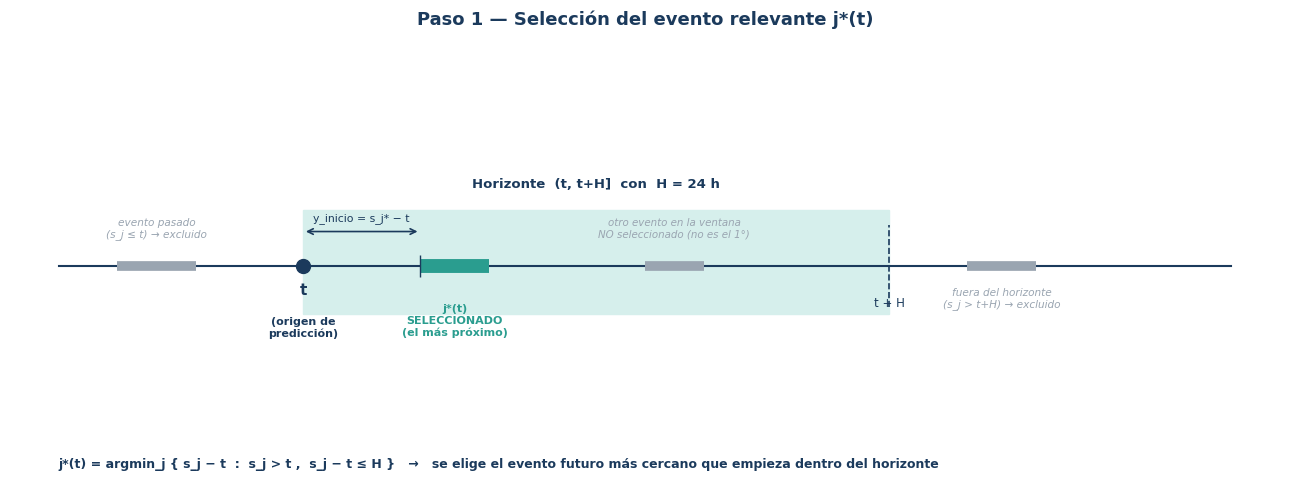

In [19]:
fig, ax = lienzo(13, 5.0, xlim=(0, 13), ylim=(0, 5.3))
ax.set_title('Paso 1 — Selección del evento relevante j*(t)', fontsize=13, color=COLOR_NAVY, fontweight='bold', pad=14)

y_line = 2.6
ax.plot([0.5, 12.5], [y_line, y_line], color=COLOR_NAVY, lw=1.5, zorder=1)

# t (origen de predicción)
t_x = 3.0
ax.plot([t_x], [y_line], marker='o', color=COLOR_NAVY, markersize=10, zorder=4)
ax.text(t_x, y_line-0.35, 't', ha='center', fontsize=11, color=COLOR_NAVY, fontweight='bold')
ax.text(t_x, y_line-0.62, '(origen de\npredicción)', ha='center', va='top', fontsize=8, color=COLOR_NAVY, fontweight='bold')

# horizonte sombreado (t, t+H]
h_end = t_x + 6.0
ax.axvspan(t_x, h_end, ymin=0.38, ymax=0.62, color=COLOR_TEAL_LT, zorder=0)
ax.plot([h_end, h_end], [y_line-0.5, y_line+0.5], color=COLOR_NAVY, lw=1.2, ls='--')
ax.text((t_x+h_end)/2, y_line+0.95, 'Horizonte  (t, t+H]  con  H = 24 h', ha='center', fontsize=9.5,
        color=COLOR_NAVY, fontweight='bold')
ax.text(h_end, y_line-0.5, 't + H', ha='center', fontsize=8.5, color=COLOR_NAVY)

# evento pasado (excluido: s_j <= t)
ax.plot([1.1, 1.9], [y_line, y_line], color=COLOR_GRAY, lw=7, solid_capstyle='butt', zorder=2)
ax.text(1.5, y_line+0.35, 'evento pasado\n(s_j ≤ t) → excluido', ha='center', fontsize=7.6, color=COLOR_GRAY, style='italic')

# evento seleccionado j*(t): el más cercano dentro del horizonte
s1, e1 = t_x+1.2, t_x+1.9
ax.plot([s1, e1], [y_line, y_line], color=COLOR_TEAL, lw=10, solid_capstyle='butt', zorder=3)
ax.plot([s1], [y_line], marker='|', color=COLOR_NAVY, markersize=16, zorder=4)
ax.text((s1+e1)/2, y_line-0.85, 'j*(t)\nSELECCIONADO\n(el más próximo)', ha='center', fontsize=8, color=COLOR_TEAL, fontweight='bold')
ax.annotate('', xy=(s1, y_line+0.42), xytext=(t_x, y_line+0.42), arrowprops=dict(arrowstyle='<->', color=COLOR_NAVY, lw=1.2))
ax.text((t_x+s1)/2, y_line+0.55, 'y_inicio = s_j* − t', ha='center', fontsize=7.8, color=COLOR_NAVY)

# segundo evento dentro del horizonte pero NO seleccionado
s2, e2 = t_x+3.5, t_x+4.1
ax.plot([s2, e2], [y_line, y_line], color=COLOR_GRAY, lw=7, solid_capstyle='butt', zorder=2)
ax.text((s2+e2)/2, y_line+0.35, 'otro evento en la ventana\nNO seleccionado (no es el 1°)', ha='center', fontsize=7.4, color=COLOR_GRAY, style='italic')

# evento fuera del horizonte (excluido: s_j > t+H)
s3, e3 = h_end+0.8, h_end+1.5
ax.plot([s3, e3], [y_line, y_line], color=COLOR_GRAY, lw=7, solid_capstyle='butt', zorder=2)
ax.text((s3+e3)/2, y_line-0.5, 'fuera del horizonte\n(s_j > t+H) → excluido', ha='center', fontsize=7.6, color=COLOR_GRAY, style='italic')

ax.text(0.5, 0.15,
        'j*(t) = argmin_j { s_j − t  :  s_j > t ,  s_j − t ≤ H }   →   se elige el evento futuro más cercano que empieza dentro del horizonte',
        fontsize=9, color=COLOR_NAVY, ha='left', fontweight='bold')

plt.tight_layout()
plt.show()

Celda 2 — Diagrama de los Pasos 2 y 3 (fórmulas + caso sin evento + control de dominio)

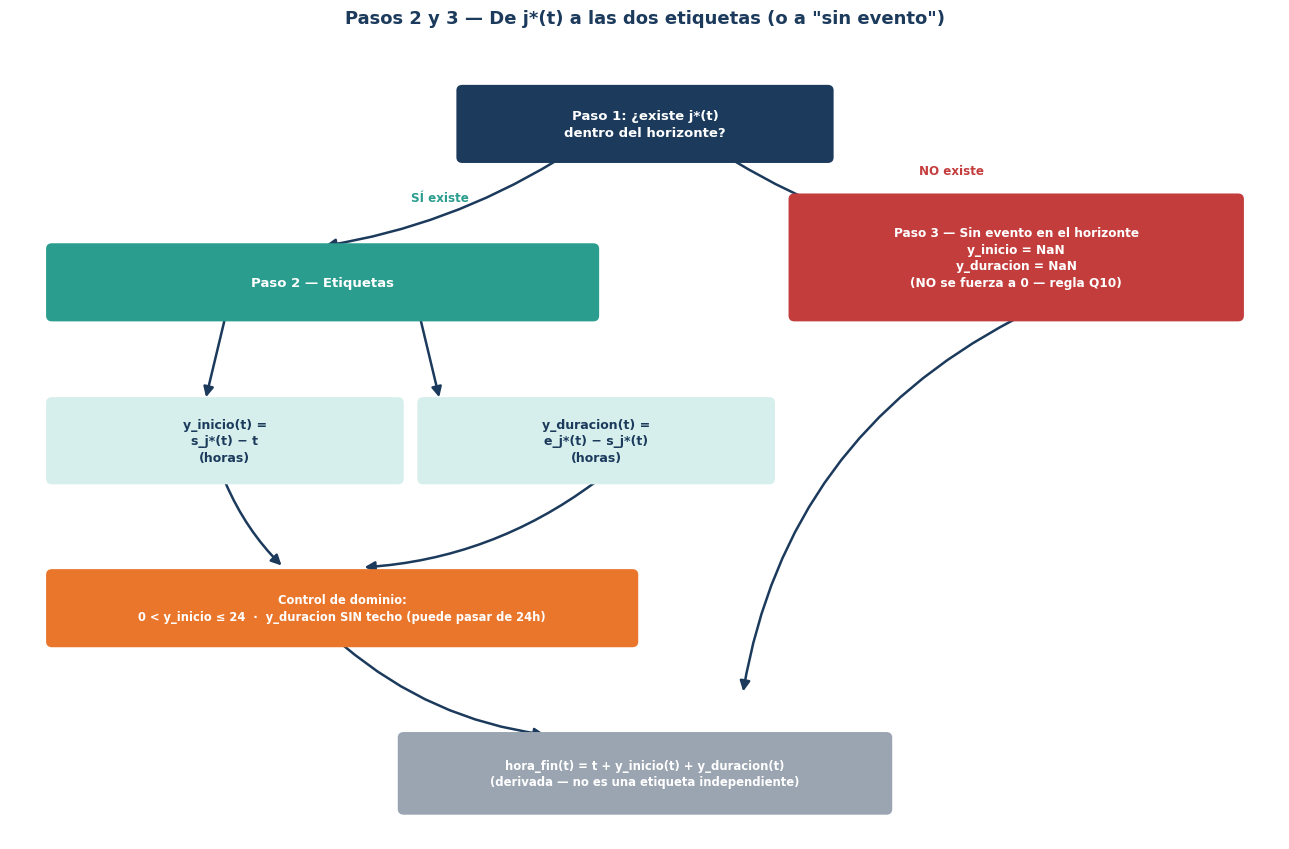

In [20]:
fig, ax = lienzo(13, 8.6, xlim=(0, 13), ylim=(0, 8.8))
ax.set_title('Pasos 2 y 3 — De j*(t) a las dos etiquetas (o a "sin evento")', fontsize=13,
             color=COLOR_NAVY, fontweight='bold', pad=14)

caja(ax, 4.6, 7.5, 3.8, 0.8, 'Paso 1: ¿existe j*(t)\ndentro del horizonte?', color=COLOR_NAVY, fontsize=9.5)

flecha(ax, (5.6, 7.5), (3.2, 6.55), rad=-0.1)
ax.text(4.1, 7.05, 'SÍ existe', fontsize=8.6, color=COLOR_TEAL, fontweight='bold')
flecha(ax, (7.4, 7.5), (9.8, 6.55), rad=0.1)
ax.text(9.3, 7.35, 'NO existe', fontsize=8.6, color=COLOR_RED, fontweight='bold')

# rama SÍ: Paso 2, dos fórmulas
caja(ax, 0.4, 5.75, 5.6, 0.8, 'Paso 2 — Etiquetas', color=COLOR_TEAL, fontsize=9.5)
flecha(ax, (2.2, 5.75), (2.0, 4.85))
flecha(ax, (4.2, 5.75), (4.4, 4.85))

caja(ax, 0.4, 3.95, 3.6, 0.9, 'y_inicio(t) =\ns_j*(t) − t\n(horas)', color=COLOR_TEAL_LT, texto_color=COLOR_NAVY, fontsize=9)
caja(ax, 4.2, 3.95, 3.6, 0.9, 'y_duracion(t) =\ne_j*(t) − s_j*(t)\n(horas)', color=COLOR_TEAL_LT, texto_color=COLOR_NAVY, fontsize=9)

flecha(ax, (2.2, 3.95), (2.8, 3.0), rad=0.1)
flecha(ax, (6.0, 3.95), (3.6, 3.0), rad=-0.15)

# control de dominio
caja(ax, 0.4, 2.15, 6.0, 0.8, 'Control de dominio:\n0 < y_inicio ≤ 24  ·  y_duracion SIN techo (puede pasar de 24h)', color=COLOR_ORANGE, fontsize=8.3)

# rama NO: Paso 3
caja(ax, 8.0, 5.75, 4.6, 1.35, 'Paso 3 — Sin evento en el horizonte\ny_inicio = NaN\ny_duracion = NaN\n(NO se fuerza a 0 — regla Q10)', color=COLOR_RED, fontsize=8.7)

# hora_fin derivada (combina ambas ramas)
flecha(ax, (3.4, 2.15), (5.5, 1.15), rad=0.15)
flecha(ax, (10.3, 5.75), (7.5, 1.6), rad=0.25)
caja(ax, 4.0, 0.3, 5.0, 0.85, 'hora_fin(t) = t + y_inicio(t) + y_duracion(t)\n(derivada — no es una etiqueta independiente)', color=COLOR_GRAY, fontsize=8.4)

plt.tight_layout()
plt.show()

## 3.4 Reglas de negocio y calidad necesarias para construir ambos targets

La formalización anterior solo es correcta si la semántica de los registros está controlada. Antes de generar las etiquetas reales deben resolverse las siguientes reglas:

1. **Cero no equivale a dato faltante.** Ausencia de un registro de indisponibilidad no debe interpretarse automáticamente como "no habrá evento"; puede ser ausencia de captura.
2. **Inicio y fin deben ser temporalmente válidos.** Un evento con `fin < inicio` es inconsistente y debe revisarse antes de derivar la duración.
3. **La causa del evento debe estar clara.** La investigación busca explicar indisponibilidad mediante condiciones meteorológicas y oceanográficas; no debe mezclarse con indisponibilidad por mantenimiento, fallas eléctricas u otras causas no climáticas.
4. **La zona horaria debe ser uniforme.** Todos los sensores (archivos Excel de variables) y el registro de eventos deben quedar en la misma referencia temporal antes de alinearse.
5. **Un solo evento por origen `t`.** El modelo, tal como se define aquí, predice el evento **más próximo** dentro del horizonte. Si existiera más de un evento en la misma ventana de 24 h, los eventos posteriores al primero **no** se incluyen en `y_inicio`/`y_duracion` de ese origen — esto debe declararse como alcance/limitación del modelo, no resolverse implícitamente.
6. **Ausencia de evento dentro del horizonte.** Los orígenes `t` sin evento válido en `(t, t+24h]` deben tratarse explícitamente (excluirlos del entrenamiento de los regresores, o usarlos como clase negativa de un clasificador previo de ocurrencia) — nunca imputarse como `y_inicio = 0` o `y_duracion = 0`.
7. **La última parte de la serie necesita tratamiento especial.** Para evaluar si existe evento dentro de las 24 h posteriores a `t`, se requiere conocer esas 24 h; las últimas observaciones del histórico pueden no tener ventana futura completa. (Para entrenamiento https://prnt.sc/lAcJQBTtgbgI)
8. **Las etiquetas futuras nunca pueden usarse como predictor.** `fecha_inicio` y `fecha_fin` del evento pertenecen a `y`, no a `X`.
9. **Las lecturas registradas DURANTE el evento tampoco son predictor de ese mismo evento.** Los valores que marcan los sensores mientras dura la indisponibilidad (Rol B, sección 3.1.1) sirven para caracterizar y validar la causa del evento, no para construir `X_≤t` — en el instante `t` de predicción esas lecturas todavía no existen.


In [ ]:
reglas_calidad_target = pd.DataFrame([
    ['Q01', 'Timestamps parseables', 'fecha_inicio y fecha_fin se convierten a datetime sin error', 'Obligatorio'],
    ['Q02', 'Orden temporal', 'fecha_fin > fecha_inicio en cada evento', 'Obligatorio'],
    ['Q03', 'Duplicados', 'eventos duplicados identificados y tratados', 'Obligatorio'],
    ['Q04', 'Causa de indisponibilidad', 'criterio de inclusión/exclusión (solo meteo-oceanográfica) documentado', 'Validar con negocio'],
    ['Q05', 'Zona horaria', 'sensores (Excel de variables) y eventos usan referencia temporal compatible', 'Obligatorio'],
    ['Q06', 'Cobertura futura', 'cada origen t tiene 24 h posteriores observables para evaluar ocurrencia', 'Obligatorio'],
    ['Q07', 'No fuga de información', 'ningún predictor contiene datos posteriores a t', 'Obligatorio'],
    ['Q08', 'Evento más próximo bien seleccionado', 'j*(t) corresponde al menor s_j - t entre los que cumplen 0 < s_j - t <= 24', 'Obligatorio'],
    ['Q09', 'Eventos múltiples en la ventana', 'regla documentada: solo se etiqueta el primero; los siguientes no generan fila adicional para ese t', 'Validar con negocio'],
    ['Q10', 'Ausencia de evento en el horizonte', 'orígenes t sin evento se excluyen o se marcan (no se fuerza y_inicio=0 / y_duracion=0)', 'Obligatorio'],
    ['Q11', 'Separación Rol A / Rol B del histórico', 'columnas *_durante_evento (caracterización) nunca se copian dentro de X_<=t', 'Obligatorio'],
], columns=['ID', 'Control', 'Criterio', 'Estado en Sprint 1'])
display(reglas_calidad_target)


,ID,Control,Criterio,Estado en Sprint 1
0,Q01,Timestamps parseables,fecha_inicio y fecha_fin se convierten a datetime sin error,Obligatorio
1,Q02,Orden temporal,fecha_fin > fecha_inicio en cada evento,Obligatorio
2,Q03,Duplicados,eventos duplicados identificados y tratados,Obligatorio
3,Q04,Causa de indisponibilidad,criterio de inclusión/exclusión (solo meteo-oceanográfica) documentado,Validar con negocio
4,Q05,Zona horaria,sensores (Excel de variables) y eventos usan referencia temporal compatible,Obligatorio
5,Q06,Cobertura futura,cada origen t tiene 24 h posteriores observables para evaluar ocurrencia,Obligatorio
6,Q07,No fuga de información,ningún predictor contiene datos posteriores a t,Obligatorio
7,Q08,Evento más próximo bien seleccionado,j*(t) corresponde al menor s_j - t entre los que cumplen 0 < s_j - t <= 24,Obligatorio
8,Q09,Eventos múltiples en la ventana,regla documentada: solo se etiqueta el primero; los siguientes no generan fila adicional para ese t,Validar con negocio
9,Q10,Ausencia de evento en el horizonte,orígenes t sin evento se excluyen o se marcan (no se fuerza y_inicio=0 / y_duracion=0),Obligatorio


**Vista visual — checklist de calidad Q01–Q11:**

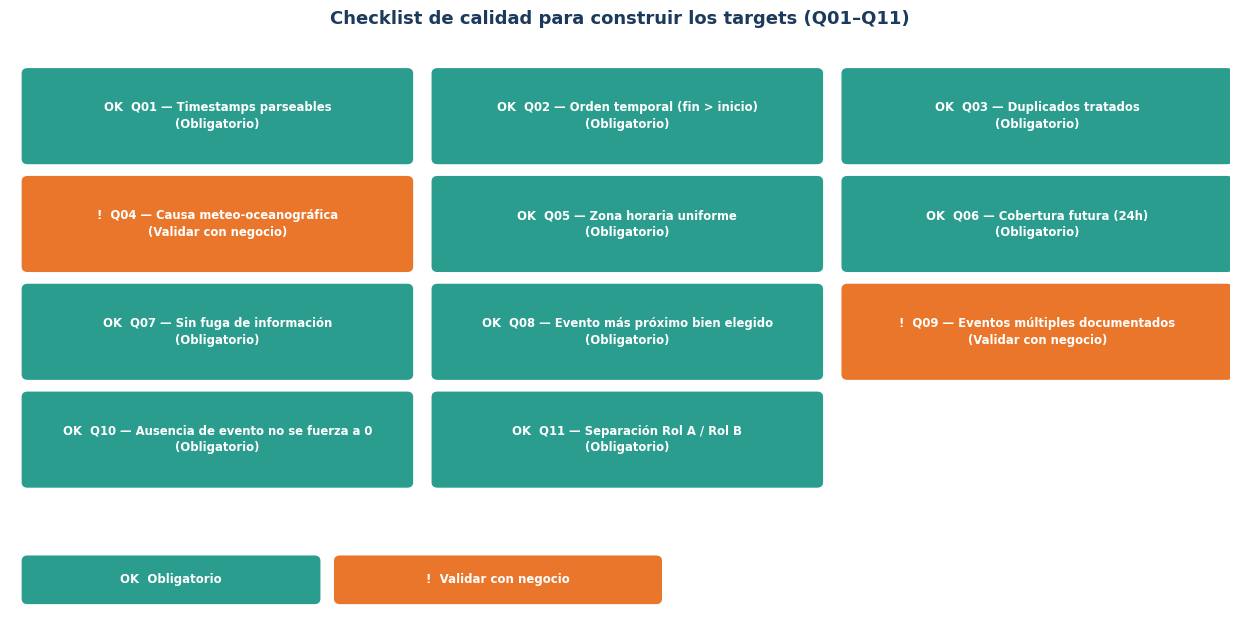

In [10]:
reglas = [
    ('Q01', 'Timestamps parseables', 'Obligatorio'),
    ('Q02', 'Orden temporal (fin > inicio)', 'Obligatorio'),
    ('Q03', 'Duplicados tratados', 'Obligatorio'),
    ('Q04', 'Causa meteo-oceanográfica', 'Validar con negocio'),
    ('Q05', 'Zona horaria uniforme', 'Obligatorio'),
    ('Q06', 'Cobertura futura (24h)', 'Obligatorio'),
    ('Q07', 'Sin fuga de información', 'Obligatorio'),
    ('Q08', 'Evento más próximo bien elegido', 'Obligatorio'),
    ('Q09', 'Eventos múltiples documentados', 'Validar con negocio'),
    ('Q10', 'Ausencia de evento no se fuerza a 0', 'Obligatorio'),
    ('Q11', 'Separación Rol A / Rol B', 'Obligatorio'),
]

fig, ax = lienzo(12.5, 6.3, xlim=(0, 12.5), ylim=(0, 6.6))
ax.set_title('Checklist de calidad para construir los targets (Q01–Q11)', fontsize=13, color=COLOR_NAVY, fontweight='bold', pad=12)

cols = 3
w, h = 3.95, 1.05
gapx, gapy = 0.25, 0.2
x0, y0 = 0.15, 5.2
for i, (qid, desc, estado) in enumerate(reglas):
    col = i % cols
    row = i // cols
    x = x0 + col * (w + gapx)
    y = y0 - row * (h + gapy)
    color = COLOR_TEAL if estado == 'Obligatorio' else COLOR_ORANGE
    icon = 'OK' if estado == 'Obligatorio' else '!'
    caja(ax, x, y, w, h, f'{icon}  {qid} — {desc}\n({estado})', color=color, fontsize=8.4)

caja(ax, 0.15, 0.1, 3.0, 0.5, 'OK  Obligatorio', color=COLOR_TEAL, fontsize=8.5)
caja(ax, 3.35, 0.1, 3.3, 0.5, '!  Validar con negocio', color=COLOR_ORANGE, fontsize=8.5)

plt.tight_layout()
plt.show()


## 3.5 Distinción crítica: valores observados vs. valores predichos

Para evitar ambigüedades en nuestra tesis y en el código, se fija la siguiente nomenclatura:

| Momento | `horas_hasta_inicio_24h` | `duracion_indisponibilidad_h` |
|---|---|---|
| Observado (histórico, *ground truth*) | `horas_hasta_inicio_24h` | `duracion_indisponibilidad_h` |
| Predicho por el modelo | `horas_hasta_inicio_24h_pred` | `duracion_indisponibilidad_h_pred` |

El fin sigue la misma lógica: `hora_fin_observada` (derivada del histórico) vs. `hora_fin_predicha` (derivada de las dos predicciones). En ningún caso la predicción debe reemplazar el registro histórico que se utiliza como referencia.

## 3.6 Arquitectura de modelado propuesta (familia GBM)

Se mantiene la familia de algoritmos ya considerada en el benchmarking del proyecto (Gradient Boosting), aplicada ahora a dos salidas sobre el mismo conjunto de predictores $X_{\le t}$. Esta sección es un **anticipo técnico para las HU de modelado (Sprint 2/3)**; en HU01 solo se deja definida la arquitectura, no se ajustan modelos finales.


In [ ]:
modelado_propuesto = pd.DataFrame([
    ['Regresor A', 'horas_hasta_inicio_24h', 'Regresión', 'XGBoost Regressor (GBM) — LightGBM y Random Forest como comparación', 'MAE, RMSE (horas)'],
    ['Regresor B', 'duracion_indisponibilidad_h', 'Regresión', 'XGBoost Regressor (GBM) — LightGBM y Random Forest como comparación', 'MAE, RMSE (horas)'],
    ['(Opcional) Clasificador previo', 'ocurre_evento_24h (0/1)', 'Clasificación', 'XGBoost Classifier / Random Forest Classifier', 'F1, AUC'],
], columns=['Componente', 'Variable objetivo', 'Tipo de tarea', 'Algoritmo candidato (familia GBM)', 'Métrica principal'])

display(modelado_propuesto)


,Componente,Variable objetivo,Tipo de tarea,Algoritmo candidato (familia GBM),Métrica principal
0,Regresor A,horas_hasta_inicio_24h,Regresión,XGBoost Regressor (GBM) — LightGBM y Random Forest como comparación,"MAE, RMSE (horas)"
1,Regresor B,duracion_indisponibilidad_h,Regresión,XGBoost Regressor (GBM) — LightGBM y Random Forest como comparación,"MAE, RMSE (horas)"
2,(Opcional) Clasificador previo,ocurre_evento_24h (0/1),Clasificación,XGBoost Classifier / Random Forest Classifier,"F1, AUC"


**Vista visual — arquitectura de modelado propuesta:**

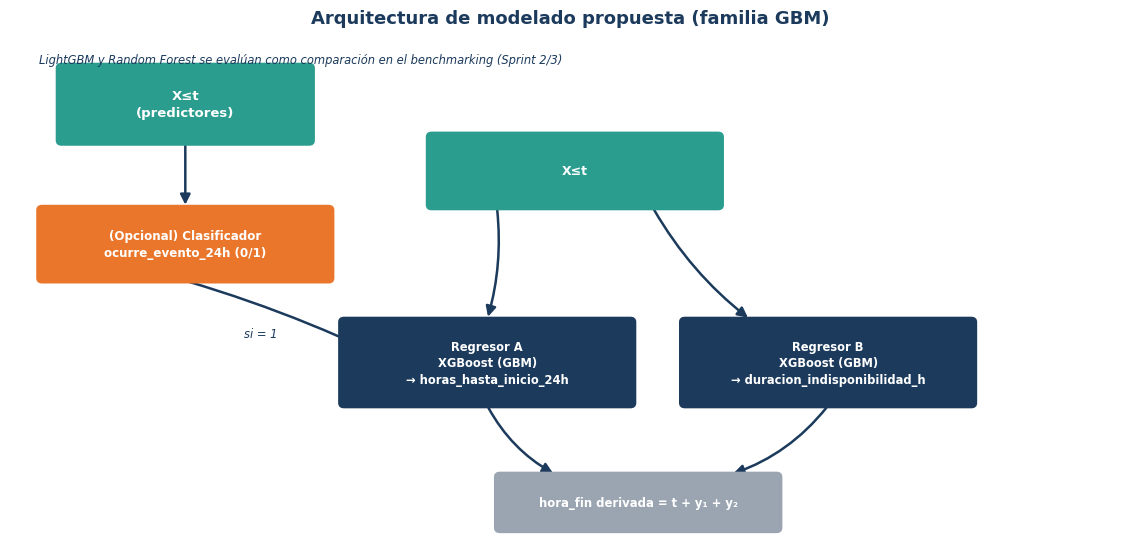

In [11]:
fig, ax = lienzo(11.5, 5.6, xlim=(0, 11.5), ylim=(0, 5.8))
ax.set_title('Arquitectura de modelado propuesta (familia GBM)', fontsize=13, color=COLOR_NAVY, fontweight='bold', pad=12)

caja(ax, 0.5, 4.6, 2.6, 0.9, 'X\u2264t\n(predictores)', color=COLOR_TEAL, fontsize=9.5)
flecha(ax, (1.8, 4.6), (1.8, 3.85))
caja(ax, 0.3, 3.0, 3.0, 0.85, '(Opcional) Clasificador\nocurre_evento_24h (0/1)', color=COLOR_ORANGE, fontsize=8.6)

flecha(ax, (1.8, 3.0), (4.3, 1.85), rad=-0.05)
ax.text(2.4, 2.35, 'si = 1', fontsize=8.3, color=COLOR_NAVY, style='italic')

caja(ax, 4.3, 3.85, 3.0, 0.85, 'X\u2264t', color=COLOR_TEAL, fontsize=9)
flecha(ax, (5.0, 3.85), (4.9, 2.55), rad=-0.1)
flecha(ax, (6.6, 3.85), (7.6, 2.55), rad=0.1)

caja(ax, 3.4, 1.55, 3.0, 1.0, 'Regresor A\nXGBoost (GBM)\n\u2192 horas_hasta_inicio_24h', color=COLOR_NAVY, fontsize=8.3)
caja(ax, 6.9, 1.55, 3.0, 1.0, 'Regresor B\nXGBoost (GBM)\n\u2192 duracion_indisponibilidad_h', color=COLOR_NAVY, fontsize=8.3)

flecha(ax, (4.9, 1.55), (5.6, 0.75), rad=0.15)
flecha(ax, (8.4, 1.55), (7.4, 0.75), rad=-0.15)
caja(ax, 5.0, 0.1, 2.9, 0.65, 'hora_fin derivada = t + y\u2081 + y\u2082', color=COLOR_GRAY, fontsize=8.4)

ax.text(0.3, 5.65, 'LightGBM y Random Forest se evalúan como comparación en el benchmarking (Sprint 2/3)',
        fontsize=8.3, color=COLOR_NAVY, style='italic', va='top')

plt.tight_layout()
plt.show()


> **Por qué sugerimos el clasificador previo, sin ser una tercera variable objetivo del alcance actual:** los dos regresores (inicio y duración) solo tienen sentido cuando existe un evento dentro del horizonte. Sin un filtro previo, el modelo se vería forzado a "inventar" un inicio y una duración incluso en ventanas de 24 h donde no ocurre ningún evento. Esta decisión queda registrada como **D07** en la tabla de decisiones abiertas (sección 4.2) para su validación con Operaciones

## 4.1 Construcción reproducible de las dos etiquetas (código)

A continuación se implementa la función que construye `horas_hasta_inicio_24h` y `duracion_indisponibilidad_h` a partir de (a) una lista de orígenes de predicción `t` y (b) el histórico de eventos con `fecha_inicio`/`fecha_fin`. Es la misma lógica formalizada en la sección 3.3, lista para aplicarse sobre los archivos Excel reales en HU03/HU04.


In [12]:
def construir_targets_evento(timestamps, df_eventos, horizonte_h=24,
                              col_inicio='fecha_inicio', col_fin='fecha_fin'):
    # Construye las dos variables objetivo (horas_hasta_inicio_24h, duracion_indisponibilidad_h)
    # para cada instante de origen t en `timestamps`, usando el histórico de eventos `df_eventos`.
    #
    # Parámetros:
    #   timestamps   : Iterable[pd.Timestamp] - instantes de origen t
    #   df_eventos   : pd.DataFrame con columnas [col_inicio, col_fin] (datetime)
    #   horizonte_h  : tamaño del horizonte en horas (por defecto 24)
    #
    # Retorna: pd.DataFrame con columnas
    #   t, ocurre_evento_24h, horas_hasta_inicio_24h, duracion_indisponibilidad_h,
    #   evento_inicio, evento_fin
    eventos = df_eventos.copy()
    eventos[col_inicio] = pd.to_datetime(eventos[col_inicio])
    eventos[col_fin] = pd.to_datetime(eventos[col_fin])
    # Q02: descartar eventos temporalmente inválidos (fin <= inicio)
    eventos = eventos[eventos[col_fin] > eventos[col_inicio]].sort_values(col_inicio).reset_index(drop=True)

    inicios = eventos[col_inicio].values
    filas = []

    for t in pd.to_datetime(pd.Series(list(timestamps))):
        limite = t + pd.Timedelta(hours=horizonte_h)
        # Candidatos: inicio estrictamente posterior a t y dentro del horizonte (t, t+H]
        mask = (eventos[col_inicio] > t) & (eventos[col_inicio] <= limite)
        candidatos = eventos.loc[mask]

        if candidatos.empty:
            filas.append({
                't': t,
                'ocurre_evento_24h': 0,
                'horas_hasta_inicio_24h': np.nan,   # Q10: no se fuerza a 0
                'duracion_indisponibilidad_h': np.nan,
                'evento_inicio': pd.NaT,
                'evento_fin': pd.NaT,
            })
            continue

        # Q08: seleccionar el evento con el inicio más próximo a t
        evento_sel = candidatos.iloc[0]  # ya viene ordenado por fecha_inicio
        y_inicio = (evento_sel[col_inicio] - t) / pd.Timedelta(hours=1)
        y_duracion = (evento_sel[col_fin] - evento_sel[col_inicio]) / pd.Timedelta(hours=1)

        filas.append({
            't': t,
            'ocurre_evento_24h': 1,
            'horas_hasta_inicio_24h': round(y_inicio, 3),
            'duracion_indisponibilidad_h': round(y_duracion, 3),
            'evento_inicio': evento_sel[col_inicio],
            'evento_fin': evento_sel[col_fin],
        })

    return pd.DataFrame(filas)


### Demostración con datos sintéticos

Los archivos Excel reales (variables meteo-oceanográficas e histórico de eventos) todavía no se integran en HU01 — eso corresponde a HU03/HU04. Para validar que la función anterior implementa correctamente la regla de negocio, se usa un histórico de eventos sintético (fechas ficticias, misma estructura `fecha_inicio`/`fecha_fin` que tendrá el Excel real) y unos orígenes `t` de ejemplo.


In [13]:
# Histórico de eventos SINTÉTICO — misma estructura que tendrá el Excel real de indisponibilidad.
# Incluye, además de fecha_inicio/fecha_fin, columnas de CARACTERIZACIÓN: lo que marcaron los
# sensores EN SIMULTÁNEO mientras el terminal estuvo indisponible (Rol B, sección 3.1.1).
# Estas columnas *_durante_evento son evidencia causal / EDA, nunca features de X_<=t.
df_eventos_demo = pd.DataFrame({
    'fecha_inicio': pd.to_datetime([
        '2026-09-16 22:35:00',
        '2026-09-17 14:10:00',
        '2026-09-17 20:25:00',   # ejemplo discutido: 17/09 20:25 -> 21:25
        '2026-09-18 03:00:00',
    ]),
    'fecha_fin': pd.to_datetime([
        '2026-09-17 01:05:00',   # duración 2.5 h
        '2026-09-17 17:40:00',   # duración 3.5 h
        '2026-09-17 21:25:00',   # duración 1.0 h
        '2026-09-18 05:00:00',   # duración 2.0 h
    ]),
    # --- columnas de caracterización (Rol B): agregadas a partir de los sensores DURANTE el evento ---
    'oleaje_max_durante_evento_m': [6.6, 6.9, 6.2, 5.8],
    'viento_max_durante_evento_mph': [12.3, 13.1, 15.4, 11.0],
    'variable_dominante': ['oleaje', 'oleaje', 'viento', 'oleaje'],
})
df_eventos_demo['duracion_h_referencia'] = (
    (df_eventos_demo['fecha_fin'] - df_eventos_demo['fecha_inicio']) / pd.Timedelta(hours=1)
)
display(df_eventos_demo)

# Orígenes de predicción t de ejemplo (incluye un caso sin evento en el horizonte)
timestamps_demo = pd.to_datetime([
    '2026-09-16 21:29:00',   # esperado: inicio ~1.1h después, duración ~2.5h
    '2026-09-17 10:00:00',   # esperado: inicio ~4.17h después, duración ~3.5h
    '2026-09-17 19:00:00',   # esperado: inicio ~1.42h después (20:25), duración 1.0h
    '2026-09-18 06:00:00',   # esperado: SIN evento en horizonte (no quedan eventos posteriores en el histórico)
])

# NOTA: construir_targets_evento SOLO usa fecha_inicio/fecha_fin (Rol A). Las columnas
# *_durante_evento no entran a esta función a propósito: no son insumo del target ni de X_<=t.
targets_demo = construir_targets_evento(timestamps_demo, df_eventos_demo, horizonte_h=24)
display(targets_demo)


,fecha_inicio,fecha_fin,oleaje_max_durante_evento_m,viento_max_durante_evento_mph,variable_dominante,duracion_h_referencia
0,2026-09-16 22:35:00,2026-09-17 01:05:00,6.6,12.3,oleaje,2.5
1,2026-09-17 14:10:00,2026-09-17 17:40:00,6.9,13.1,oleaje,3.5
2,2026-09-17 20:25:00,2026-09-17 21:25:00,6.2,15.4,viento,1.0
3,2026-09-18 03:00:00,2026-09-18 05:00:00,5.8,11.0,oleaje,2.0


,t,ocurre_evento_24h,horas_hasta_inicio_24h,duracion_indisponibilidad_h,evento_inicio,evento_fin
0,2026-09-16 21:29:00,1,1.100,2.5,2026-09-16 22:35:00,2026-09-17 01:05:00
1,2026-09-17 10:00:00,1,4.167,3.5,2026-09-17 14:10:00,2026-09-17 17:40:00
2,2026-09-17 19:00:00,1,1.417,1.0,2026-09-17 20:25:00,2026-09-17 21:25:00
3,2026-09-18 06:00:00,0,NaN,NaN,NaT,NaT


La primera fila reproduce exactamente el caso discutido en la definición del problema: lanzando la predicción a las 21:29 del 16/09, el próximo evento inicia ~1.1 h después (22:35) y dura 2.5 h — consistente con `fin = t + y_inicio + y_duracion`. La tercera fila reproduce el caso de 20:25→21:25: lanzando la predicción a las 19:00, el evento inicia ~1.42 h después y dura 1.0 h. La cuarta fila muestra el comportamiento esperado cuando no hay evento dentro del horizonte: ambas etiquetas quedan en `NaN` y `ocurre_evento_24h = 0`, en vez de forzarse a cero (regla Q10).

Nótese que `oleaje_max_durante_evento_m`, `viento_max_durante_evento_mph` y `variable_dominante` **no aparecen** en `targets_demo`: quedaron deliberadamente fuera de `construir_targets_evento`, porque son datos del Rol B (caracterización) y solo tienen sentido una vez que el evento ya ocurrió — usarlos como si fueran conocidos en el instante `t` sería exactamente el data leakage que blinda la regla Q07.

## 4.2 Prueba de humo del pipeline con GBM (XGBoost)

Este bloque **no busca resultados válidos de tesis** — el dataset es sintético y demasiado pequeño para entrenar nada real. Su único propósito es confirmar que la arquitectura de dos regresores GBM (sección 3.6) es compatible con la estructura de `X_{\le t}` y con las etiquetas que produce `construir_targets_evento`, antes de aplicarla sobre los datos reales en las HU de modelado.


In [14]:
from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error

rng = np.random.default_rng(42)
n = 300

# X_<=t SINTÉTICO: agregados de lookback (media/máx de las últimas horas) por variable meteo-oceanográfica.
# En HU03/HU04 estas columnas se calculan a partir de los archivos Excel reales, no se simulan.
X_demo = pd.DataFrame({
    'viento_media_24h_mph': rng.normal(10.5, 1.5, n),
    'viento_max_24h_mph': rng.normal(13.0, 2.0, n),
    'oleaje_media_24h_m': rng.normal(4.8, 0.9, n),
    'oleaje_max_24h_m': rng.normal(6.2, 1.1, n),
    'temperatura_media_24h_c': rng.normal(18.9, 0.4, n),
    'humedad_media_24h_pct': rng.normal(84.5, 0.5, n),
    'presion_media_24h_hpa': rng.normal(1012.5, 0.6, n),
})

# Etiquetas SINTÉTICAS con una relación simulada al oleaje/viento, solo para probar que el pipeline corre.
y_inicio_demo = np.clip(24 - (X_demo['oleaje_max_24h_m'] - 4) * 3 + rng.normal(0, 1.5, n), 0.1, 24)
y_duracion_demo = np.clip((X_demo['oleaje_media_24h_m'] - 3) * 1.2 + rng.normal(0, 0.5, n), 0.2, None)

X_train, X_test, yi_train, yi_test, yd_train, yd_test = train_test_split(
    X_demo, y_inicio_demo, y_duracion_demo, test_size=0.25, random_state=42
)

modelo_inicio = XGBRegressor(n_estimators=200, max_depth=3, learning_rate=0.08, random_state=42)
modelo_duracion = XGBRegressor(n_estimators=200, max_depth=3, learning_rate=0.08, random_state=42)

modelo_inicio.fit(X_train, yi_train)
modelo_duracion.fit(X_train, yd_train)

pred_inicio = modelo_inicio.predict(X_test)
pred_duracion = modelo_duracion.predict(X_test)

mae_inicio = mean_absolute_error(yi_test, pred_inicio)
mae_duracion = mean_absolute_error(yd_test, pred_duracion)

resumen_smoke_test = pd.DataFrame([
    ['Regresor A (horas_hasta_inicio_24h)', 'XGBRegressor (GBM)', round(mae_inicio, 3)],
    ['Regresor B (duracion_indisponibilidad_h)', 'XGBRegressor (GBM)', round(mae_duracion, 3)],
], columns=['Componente', 'Algoritmo', 'MAE (horas) — dato sintético, solo smoke test'])

display(resumen_smoke_test)
print('Pipeline ejecutado correctamente. Reemplazar X_demo/y_*_demo por los datos reales en HU03/HU04.')


,Componente,Algoritmo,"MAE (horas) — dato sintético, solo smoke test"
0,Regresor A (horas_hasta_inicio_24h),XGBRegressor (GBM),1.275
1,Regresor B (duracion_indisponibilidad_h),XGBRegressor (GBM),0.475


Pipeline ejecutado correctamente. Reemplazar X_demo/y_*_demo por los datos reales en HU03/HU04.


**Vista visual — resultado de la prueba de humo (MAE por regresor):**

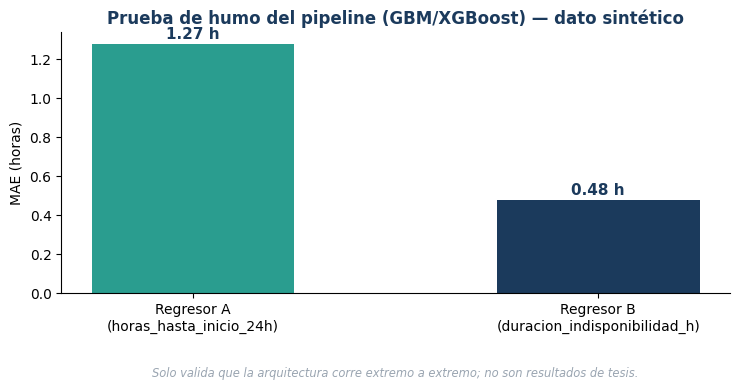

In [15]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
bars = ax.bar(['Regresor A\n(horas_hasta_inicio_24h)', 'Regresor B\n(duracion_indisponibilidad_h)'],
              [mae_inicio, mae_duracion], color=[COLOR_TEAL, COLOR_NAVY], width=0.5)
for b, v in zip(bars, [mae_inicio, mae_duracion]):
    ax.text(b.get_x() + b.get_width()/2, v + 0.03, f'{v:.2f} h', ha='center', fontsize=11, fontweight='bold', color=COLOR_NAVY)
ax.set_ylabel('MAE (horas)', fontsize=10)
ax.set_title('Prueba de humo del pipeline (GBM/XGBoost) — dato sintético', fontsize=12, color=COLOR_NAVY, fontweight='bold')
ax.spines[['top', 'right']].set_visible(False)
ax.text(0.5, -0.32, 'Solo valida que la arquitectura corre extremo a extremo; no son resultados de tesis.',
        transform=ax.transAxes, ha='center', fontsize=8.3, color=COLOR_GRAY, style='italic')
plt.tight_layout()
plt.show()


## 4.3 Riesgos de definición que deben cerrarse antes de HU03/HU04

Estas preguntas no deben resolverse por suposición del equipo de Data Science. Requieren evidencia del dataset o validación con el responsable operativo:

- ¿La indisponibilidad histórica está registrada a nivel de los procesos operativos expuestos?
- ¿Todos los registros de indisponibilidad corresponden a causas meteo-oceanográficas?
- ¿Un período sin registro significa **operación normal** o **ausencia de captura**?
- ¿Los timestamps de los archivos Excel de variables y del histórico de eventos usan la misma zona horaria y convención de fecha?
- ¿Pueden existir varios eventos dentro de una misma ventana de 24 h?
- ¿La duración ya calculada en el sistema (si existe) coincide con `fecha_fin - fecha_inicio`?
- ¿Qué hacer operativamente con los orígenes `t` que no tienen evento dentro del horizonte: excluirlos del entrenamiento de los regresores o entrenar primero un clasificador de ocurrencia?

Responder estas preguntas forma parte de la calidad de la **comprensión de datos** y protege al proyecto contra etiquetas técnicamente calculables pero semánticamente incorrectas.


In [ ]:
decisiones_abiertas = pd.DataFrame([
    ['D01', 'Nivel de la indisponibilidad', 'Terminal vs. maniobra/activo', 'Operaciones / dueño del dato', 'Antes de construir el target final'],
    ['D02', 'Causa del evento', 'Solo meteo-oceanográfica vs. toda indisponibilidad', 'Operaciones / dueño del dato', 'Antes de filtrar históricos'],
    ['D03', 'Ausencia de registro', 'Cero real vs. dato faltante', 'Dueño del dato + Data/ML', 'Antes del EDA'],
    ['D04', 'Zona horaria', 'Referencia temporal oficial entre Excel de variables e histórico de eventos', 'Dueño de sensores / Data/ML', 'Antes de integrar fuentes'],
    ['D05', 'Horizonte operativo', 'Ratificar 24 h como horizonte principal', 'Operaciones / Product Owner', 'Durante Sprint 1'],
    ['D06', 'Eventos múltiples en el horizonte', 'Predecir solo el más próximo vs. modelar una lista/secuencia de eventos', 'Operaciones + Data/ML', 'Antes de HU05/HU06 (modelado)'],
    ['D07', 'Ausencia de evento en el horizonte', 'Excluir del entrenamiento vs. clasificador previo de ocurrencia (0/1)', 'Data/ML + Product Owner', 'Antes de HU05/HU06 (modelado)'],
], columns=['ID', 'Decisión', 'Alternativas a cerrar', 'Responsable sugerido', 'Momento'])
display(decisiones_abiertas)


,ID,Decisión,Alternativas a cerrar,Responsable sugerido,Momento
0,D01,Nivel de la indisponibilidad,Terminal vs. maniobra/activo,Operaciones / dueño del dato,Antes de construir el target final
1,D02,Causa del evento,Solo meteo-oceanográfica vs. toda indisponibilidad,Operaciones / dueño del dato,Antes de filtrar históricos
2,D03,Ausencia de registro,Cero real vs. dato faltante,Dueño del dato + Data/ML,Antes del EDA
3,D04,Zona horaria,Referencia temporal oficial entre Excel de variables e histórico de eventos,Dueño de sensores / Data/ML,Antes de integrar fuentes
4,D05,Horizonte operativo,Ratificar 24 h como horizonte principal,Operaciones / Product Owner,Durante Sprint 1
5,D06,Eventos múltiples en el horizonte,Predecir solo el más próximo vs. modelar una lista/secuencia de eventos,Operaciones + Data/ML,Antes de HU05/HU06 (modelado)
6,D07,Ausencia de evento en el horizonte,Excluir del entrenamiento vs. clasificador previo de ocurrencia (0/1),Data/ML + Product Owner,Antes de HU05/HU06 (modelado)


**Vista visual — decisiones abiertas D01–D07:**

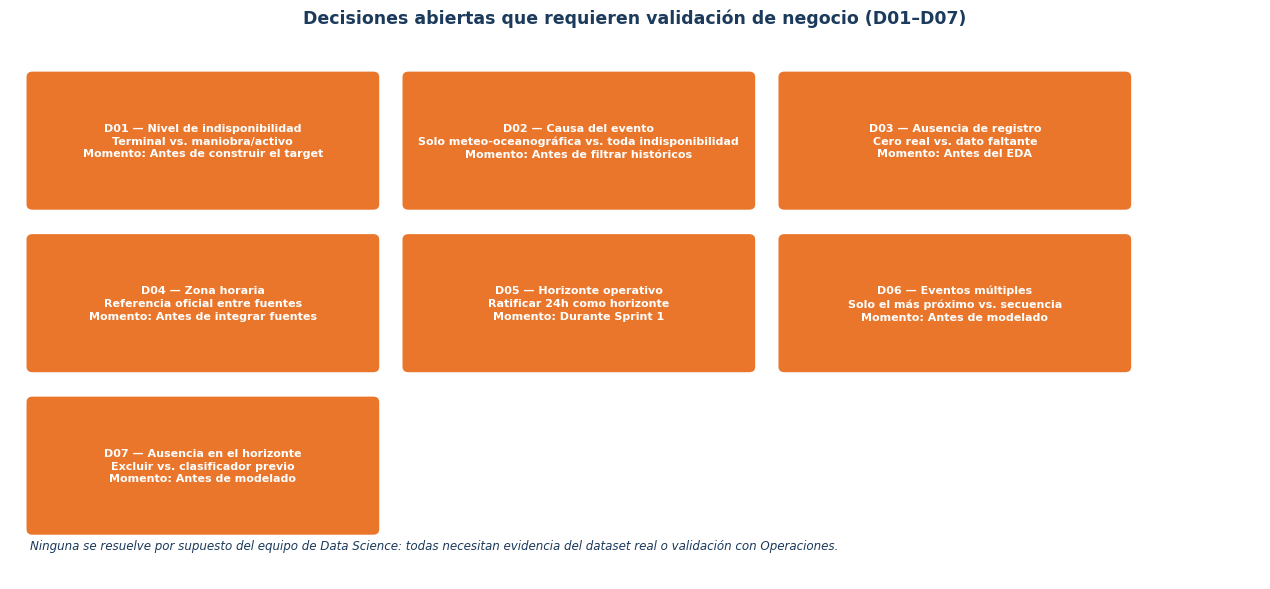

In [16]:
decisiones_vis = [
    ('D01', 'Nivel de indisponibilidad', 'Terminal vs. maniobra/activo', 'Antes de construir el target'),
    ('D02', 'Causa del evento', 'Solo meteo-oceanográfica vs. toda indisponibilidad', 'Antes de filtrar históricos'),
    ('D03', 'Ausencia de registro', 'Cero real vs. dato faltante', 'Antes del EDA'),
    ('D04', 'Zona horaria', 'Referencia oficial entre fuentes', 'Antes de integrar fuentes'),
    ('D05', 'Horizonte operativo', 'Ratificar 24h como horizonte', 'Durante Sprint 1'),
    ('D06', 'Eventos múltiples', 'Solo el más próximo vs. secuencia', 'Antes de modelado'),
    ('D07', 'Ausencia en el horizonte', 'Excluir vs. clasificador previo', 'Antes de modelado'),
]

fig, ax = lienzo(12.8, 6.0, xlim=(0, 12.8), ylim=(0, 6.3))
ax.set_title('Decisiones abiertas que requieren validación de negocio (D01–D07)', fontsize=12.5, color=COLOR_NAVY, fontweight='bold', pad=12)

w, h = 3.55, 1.55
gapx, gapy = 0.3, 0.35
cols = 3
x0, y0 = 0.2, 4.35
for i, (did, tema, alt, momento) in enumerate(decisiones_vis):
    col = i % cols
    row = i // cols
    x = x0 + col * (w + gapx)
    y = y0 - row * (h + gapy)
    caja(ax, x, y, w, h, f'{did} — {tema}\n{alt}\nMomento: {momento}', color=COLOR_ORANGE, fontsize=8.0)

ax.text(0.2, 0.35, 'Ninguna se resuelve por supuesto del equipo de Data Science: todas necesitan evidencia del dataset real o validación con Operaciones.',
        fontsize=8.6, color=COLOR_NAVY, style='italic')

plt.tight_layout()
plt.show()


# 5. Definition of Done — HU01 / T01 / T02

La HU01 puede considerarse metodológicamente terminada cuando los siguientes artefactos queden revisados y versionados:

| Entregable | Tarea | Evidencia esperada | Estado inicial |
|---|---|---|---|
| Declaración del problema de negocio | T01 | Texto aprobado y alineado con el proceso *As-Is* | Definido en el documento base |
| Mapa problema → necesidad → salida predictiva | T01 | Matriz de trazabilidad | Incluido en este notebook |
| Pregunta predictiva formal (doble salida) | T01 | `X_(≤t) → (y_inicio, y_duracion)` | Incluido en este notebook |
| Ficha técnica de AMBAS variables objetivo | T02 | Nombre, unidad, tipo, horizonte, fuente y reglas para inicio y duración | Incluido en este notebook |
| Regla matemática de construcción de `y_inicio` y `y_duracion` | T02 | Fórmula reproducible + función `construir_targets_evento` | Incluido en este notebook (código) |
| Fuentes de datos identificadas (Excel por variable + histórico de eventos) | T02 | Tabla de fuentes con columnas clave y granularidad | Incluido en este notebook |
| Arquitectura de modelado (familia GBM) | T02 | Tabla de componentes (regresores + clasificador opcional) y smoke test | Incluido en este notebook |
| Decisiones semánticas abiertas | T02 | Acta/validación con experto de negocio | Pendiente de validación |
| Controles mínimos de calidad | T02 | Checklist antes de generar las etiquetas finales | Incluido en este notebook |

> **Nota de gobernanza:** "incluido" no significa "aprobado por Operaciones". Las decisiones que cambian el significado del dato deben conservar evidencia de validación con el dueño del proceso o del dato.


In [17]:
dod = pd.DataFrame([
    ['T01', 'Problema de negocio formulado sin depender del algoritmo', 'CUMPLE - formulado'],
    ['T01', 'Proceso reactivo As-Is identificado', 'CUMPLE - documentado'],
    ['T01', 'Traducción a problema de regresión de doble salida', 'CUMPLE - formalizado'],
    ['T02', 'Dos variables objetivo continuas y en horas (inicio, duración)', 'CUMPLE - definidas'],
    ['T02', 'Unidad temporal horaria', 'CUMPLE - definida en documento base'],
    ['T02', 'Horizonte de 24 horas (evento dentro de la ventana)', 'CUMPLE - definido y formalizado'],
    ['T02', 'Fuentes de datos (Excel por variable + histórico de eventos)', 'CUMPLE - inventariadas'],
    ['T02', 'Función reproducible de construcción de targets', 'CUMPLE - implementada y probada con datos sintéticos'],
    ['T02', 'Arquitectura de modelado GBM (2 regresores + clasificador opcional)', 'CUMPLE - definida y validada con smoke test'],
    ['T02', 'Reglas de eventos múltiples y ausencia de evento', 'PENDIENTE - validar con negocio (D06, D07)'],
    ['T02', 'Cero vs. faltante y zona horaria', 'PENDIENTE - verificar con datos reales'],
], columns=['Tarea', 'Criterio', 'Estado'])
display(dod)


,Tarea,Criterio,Estado
0,T01,Problema de negocio formulado sin depender del algoritmo,CUMPLE - formulado
1,T01,Proceso reactivo As-Is identificado,CUMPLE - documentado
2,T01,Traducción a problema de regresión de doble salida,CUMPLE - formalizado
3,T02,"Dos variables objetivo continuas y en horas (inicio, duración)",CUMPLE - definidas
4,T02,Unidad temporal horaria,CUMPLE - definida en documento base
5,T02,Horizonte de 24 horas (evento dentro de la ventana),CUMPLE - definido y formalizado
6,T02,Fuentes de datos (Excel por variable + histórico de eventos),CUMPLE - inventariadas
7,T02,Función reproducible de construcción de targets,CUMPLE - implementada y probada con datos sintéticos
8,T02,Arquitectura de modelado GBM (2 regresores + clasificador opcional),CUMPLE - definida y validada con smoke test
9,T02,Reglas de eventos múltiples y ausencia de evento,"PENDIENTE - validar con negocio (D06, D07)"


**Vista visual — tablero de cierre (Definition of Done):**

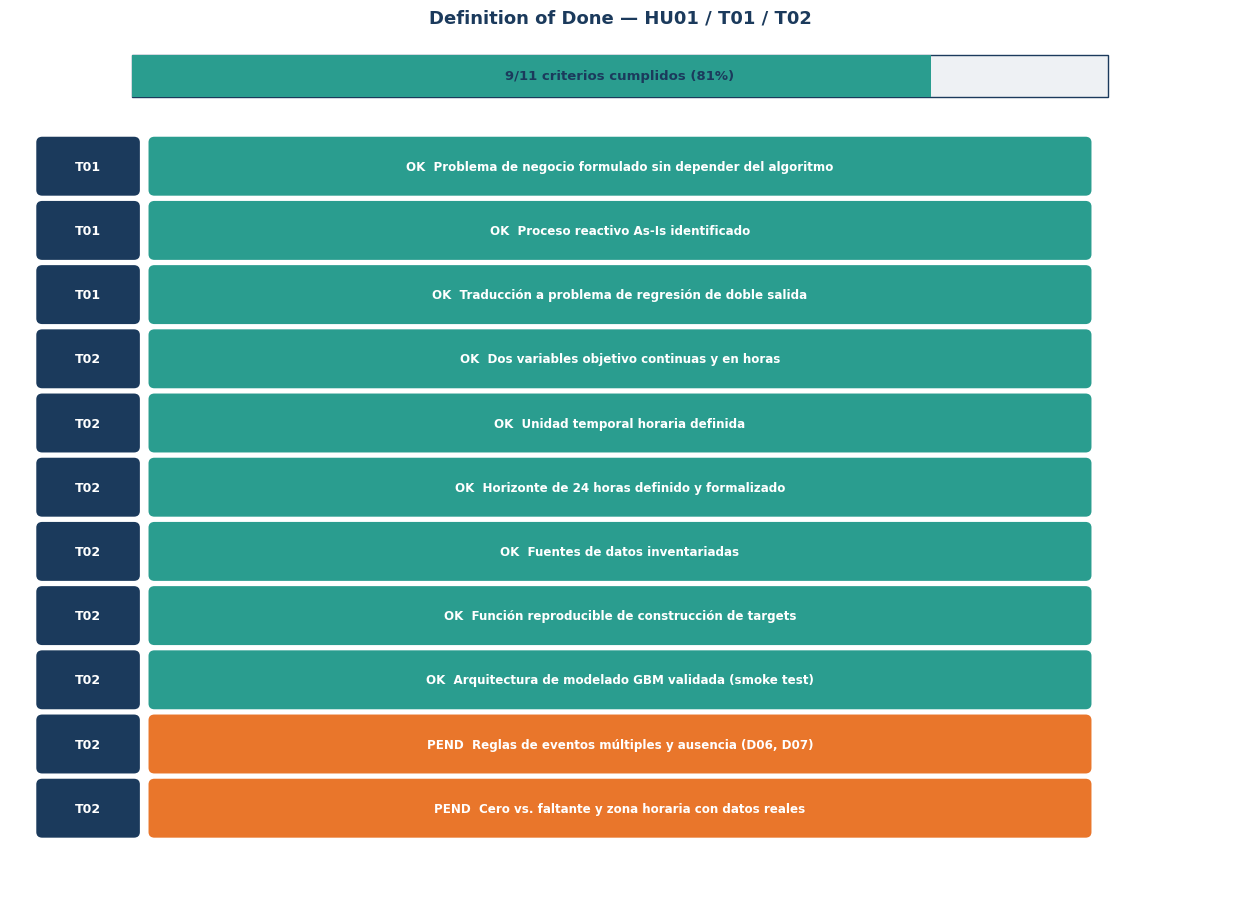

In [18]:
items_dod = [
    ('T01', 'Problema de negocio formulado sin depender del algoritmo', 'ok'),
    ('T01', 'Proceso reactivo As-Is identificado', 'ok'),
    ('T01', 'Traducción a problema de regresión de doble salida', 'ok'),
    ('T02', 'Dos variables objetivo continuas y en horas', 'ok'),
    ('T02', 'Unidad temporal horaria definida', 'ok'),
    ('T02', 'Horizonte de 24 horas definido y formalizado', 'ok'),
    ('T02', 'Fuentes de datos inventariadas', 'ok'),
    ('T02', 'Función reproducible de construcción de targets', 'ok'),
    ('T02', 'Arquitectura de modelado GBM validada (smoke test)', 'ok'),
    ('T02', 'Reglas de eventos múltiples y ausencia (D06, D07)', 'pend'),
    ('T02', 'Cero vs. faltante y zona horaria con datos reales', 'pend'),
]
n_ok = sum(1 for _, _, e in items_dod if e == 'ok')
n_total = len(items_dod)

fig, ax = lienzo(12.5, 9.2, xlim=(0, 12.5), ylim=(0, 9.4))
ax.set_title('Definition of Done — HU01 / T01 / T02', fontsize=13, color=COLOR_NAVY, fontweight='bold', pad=10)

bar_w = 10.0
ax.add_patch(Rectangle((1.25, 8.75), bar_w, 0.45, facecolor=COLOR_GRAY_LT, edgecolor=COLOR_NAVY, lw=1))
ax.add_patch(Rectangle((1.25, 8.75), bar_w * n_ok / n_total, 0.45, facecolor=COLOR_TEAL))
ax.text(1.25 + bar_w/2, 8.975, f'{n_ok}/{n_total} criterios cumplidos ({100*n_ok//n_total}%)', ha='center', va='center', fontsize=9.5, fontweight='bold', color=COLOR_NAVY)

y = 8.05
for tarea, texto, estado in items_dod:
    color = COLOR_TEAL if estado == 'ok' else COLOR_ORANGE
    icon = 'OK' if estado == 'ok' else 'PEND'
    caja(ax, 0.3, y - 0.35, 1.0, 0.58, tarea, color=COLOR_NAVY, fontsize=9)
    caja(ax, 1.45, y - 0.35, 9.6, 0.58, f'{icon}  {texto}', color=color, fontsize=8.6, texto_color='white')
    y -= 0.7

plt.tight_layout()
plt.show()
